# STAYCAST AI - Data understanding, EDA and target construction
**Dataset:** Hotel Booking Demand (Antonio, Almeida & Nunes, 2019; CC BY 4.0) - 119,390 bookings, two Portuguese hotels, arrivals 2015-07-01 to 2017-08-31.

> **Important:** the file holds *bookings*, not daily occupancy snapshots and not room inventory. The target built here is **net booking room-night demand per stay date and reserved room category**. It is never described as occupancy %.

Every chart below is produced by `src/eda.py`; the interpretation under each chart is generated from the plotted numbers.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Markdown, display
from src import config, eda
pd.set_option('display.max_colwidth', 80, 'display.width', 160)
d = eda.EDAData()
def show(name):
    fig, txt = eda.ALL_FIGURES[name](d)
    fig.tight_layout(); display(fig); display(Markdown('**Business interpretation.** ' + txt))


## 1. Dimensions, columns and data types

In [2]:
print('Raw shape:', d.raw.drop(columns=['arrival_date','adr_w']).shape)
eda.schema_table(d.raw)

Raw shape: (119390, 32)


,dtype,missing,NULL_string,description
hotel,str,0,0,Resort Hotel or City Hotel (two Portuguese properties)
is_canceled,int64,0,0,1 if the booking was cancelled (known only after the outcome)
lead_time,int64,0,0,Days between booking entry and arrival
arrival_date_year,int64,0,0,Year of arrival
arrival_date_month,str,0,0,Month name of arrival
arrival_date_week_number,int64,0,0,ISO week of arrival
arrival_date_day_of_month,int64,0,0,Day of arrival
stays_in_weekend_nights,int64,0,0,Saturday/Sunday nights booked
stays_in_week_nights,int64,0,0,Mon-Fri nights booked
adults,int64,0,0,Number of adults


## 2. Missing values

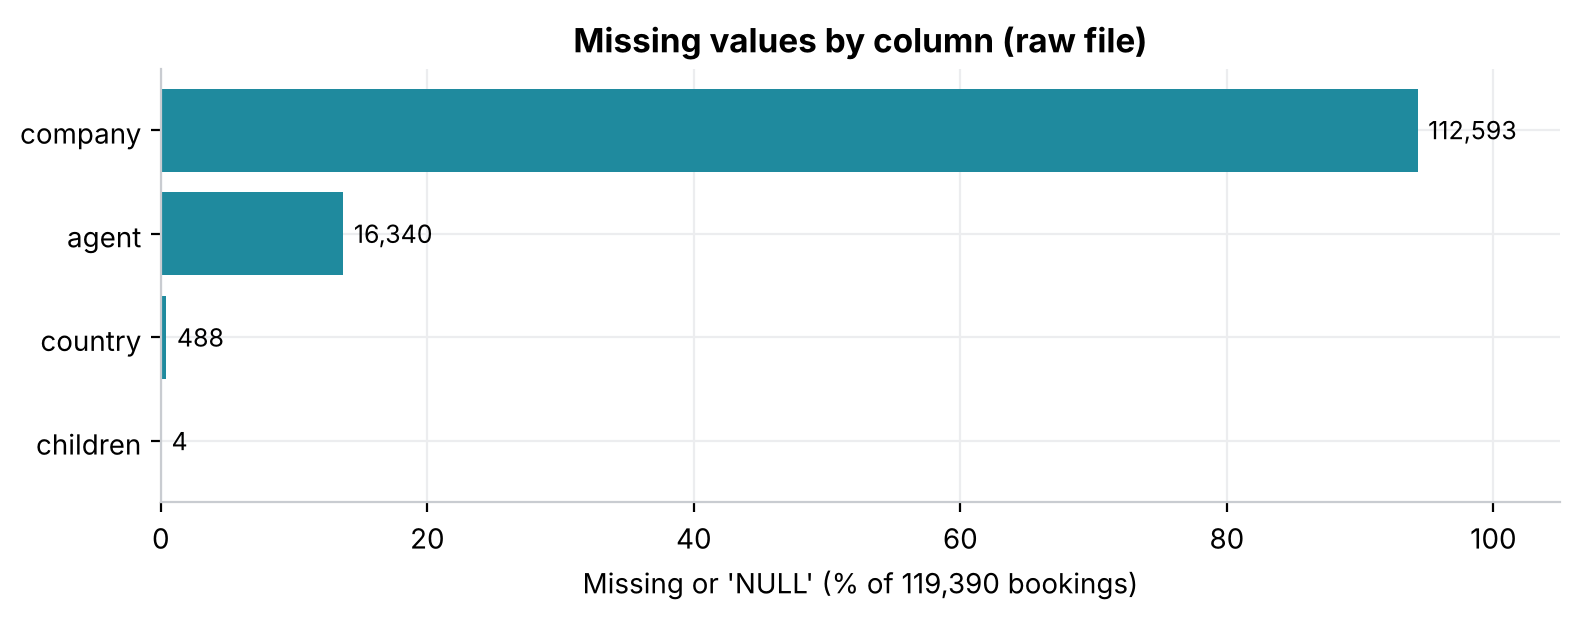

**Business interpretation.** `company` is missing for 94% and `agent` for 14% of bookings, so neither is used as a forecasting feature. Only 4 `children` and 488 `country` values are missing - harmless for a demand forecast.

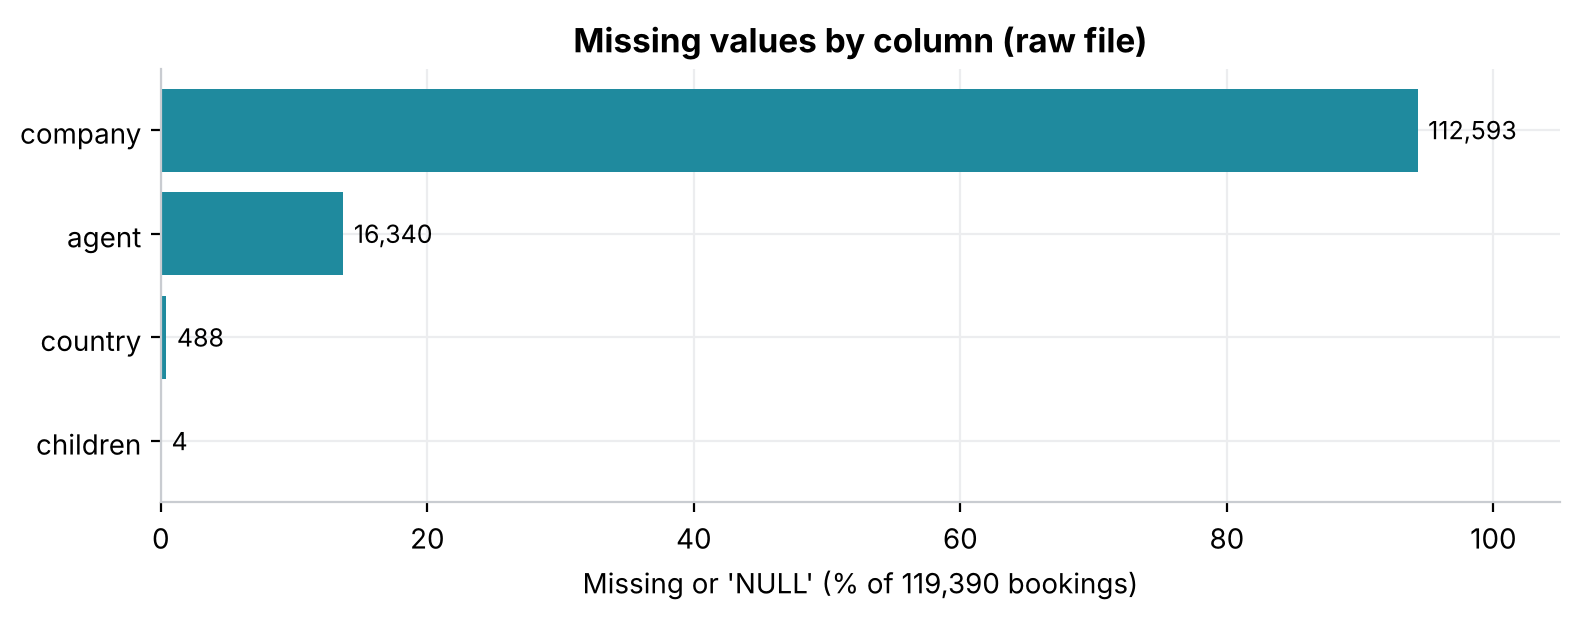

In [3]:
show('missing_values')

## 3. Duplicates
There is no booking ID, so identical rows cannot be proven to be the same booking. The decision (drop exact copies) is tested for sensitivity below.

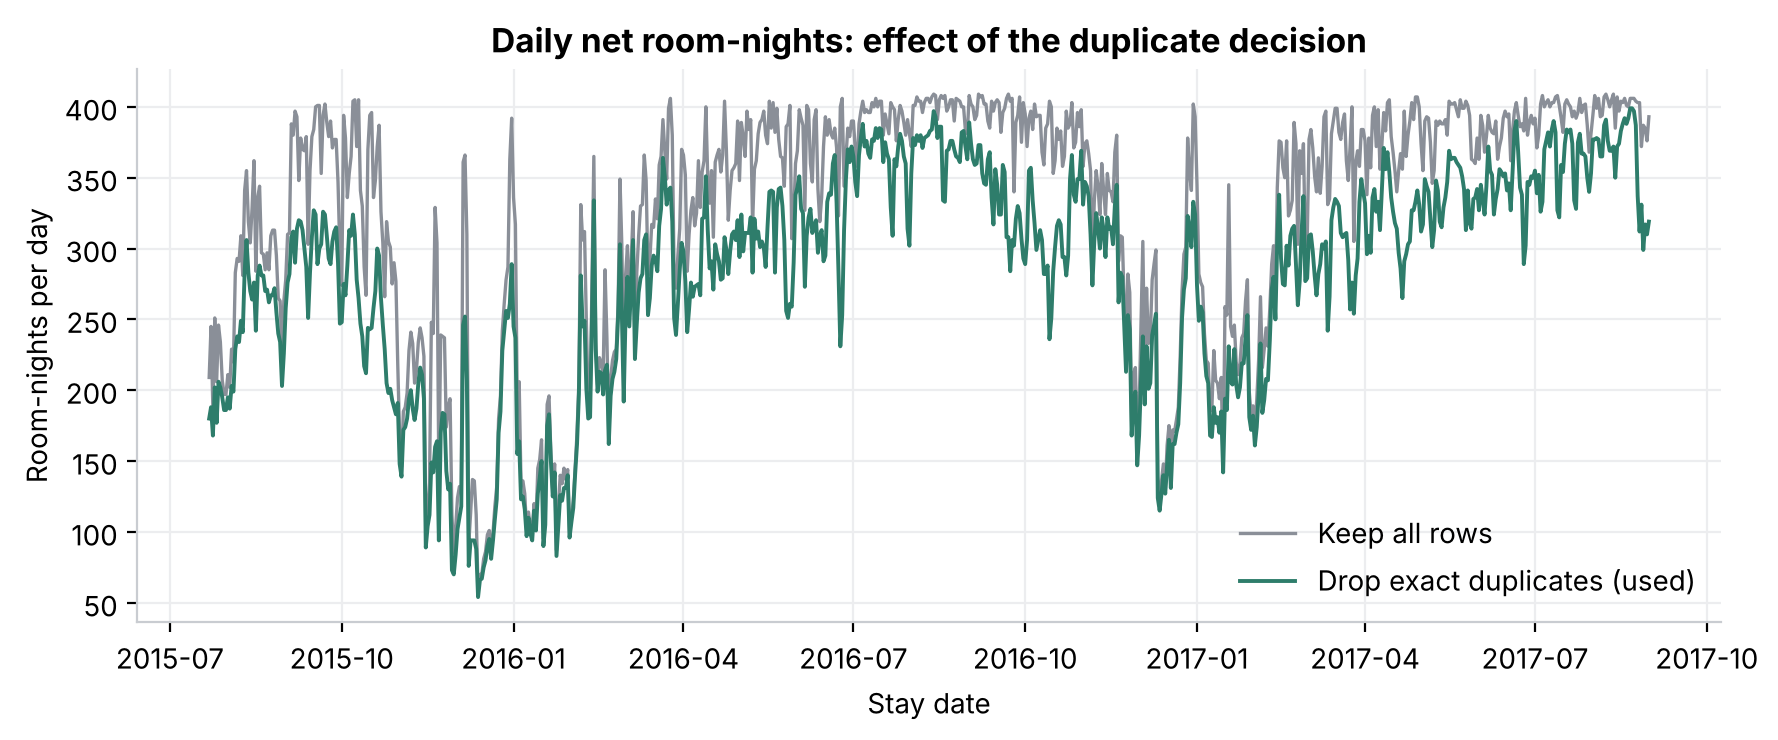

**Business interpretation.** 31,994 rows (26.8%) are exact copies of another row. Dropping them lowers total room-nights to 86% of the keep-all level but the two daily series have correlation 0.942, so weekly/seasonal shape - what a forecaster learns - is unchanged. The absolute level may be understated if some copies are genuine repeat bookings (no booking ID exists to prove either way).

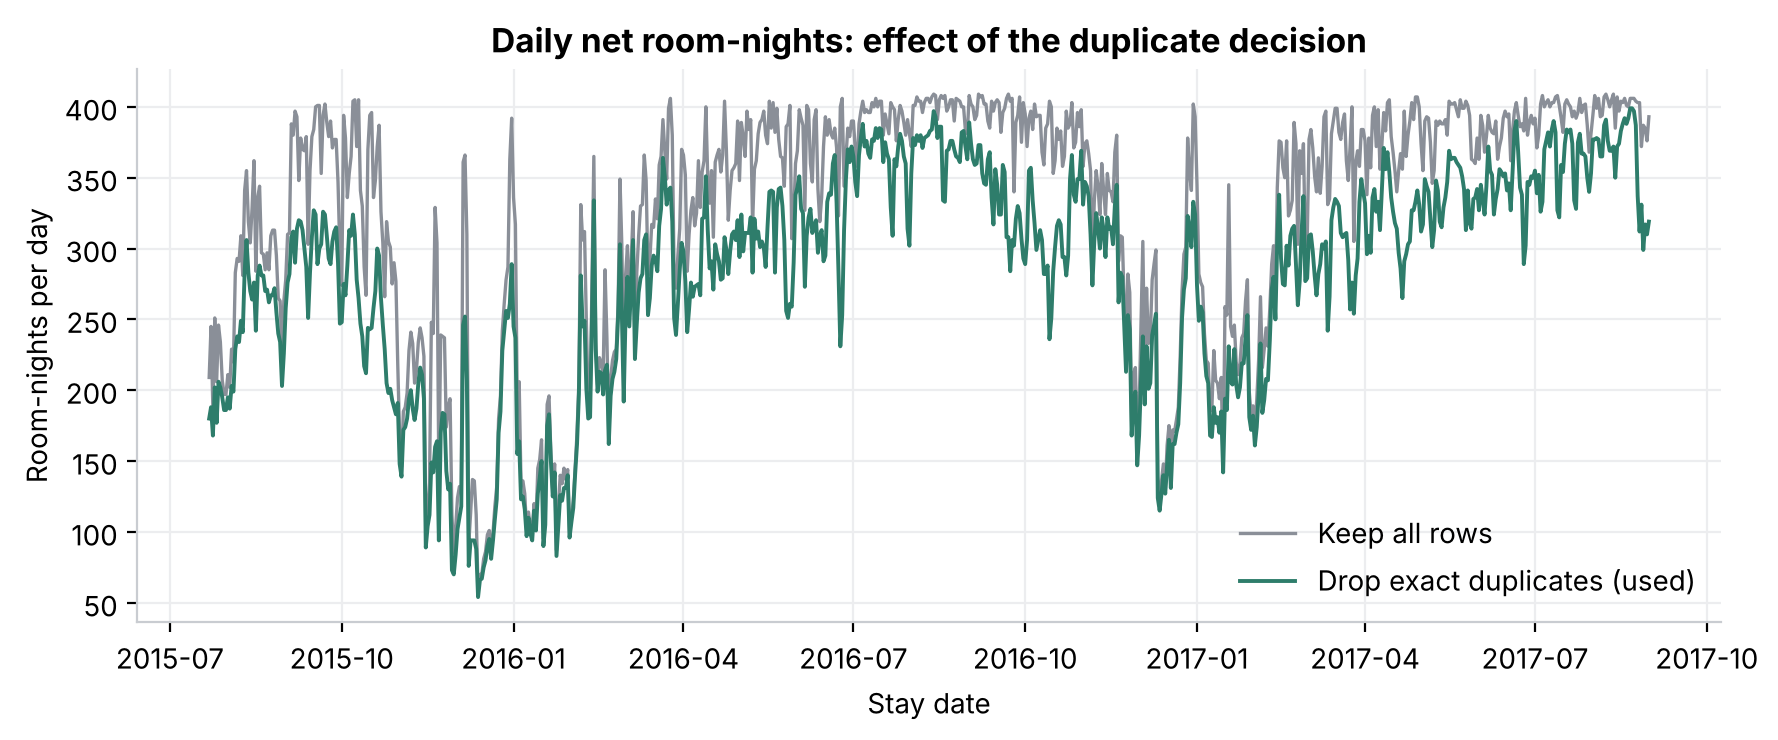

In [4]:
show('duplicates_sensitivity')

## 4. Cancellations

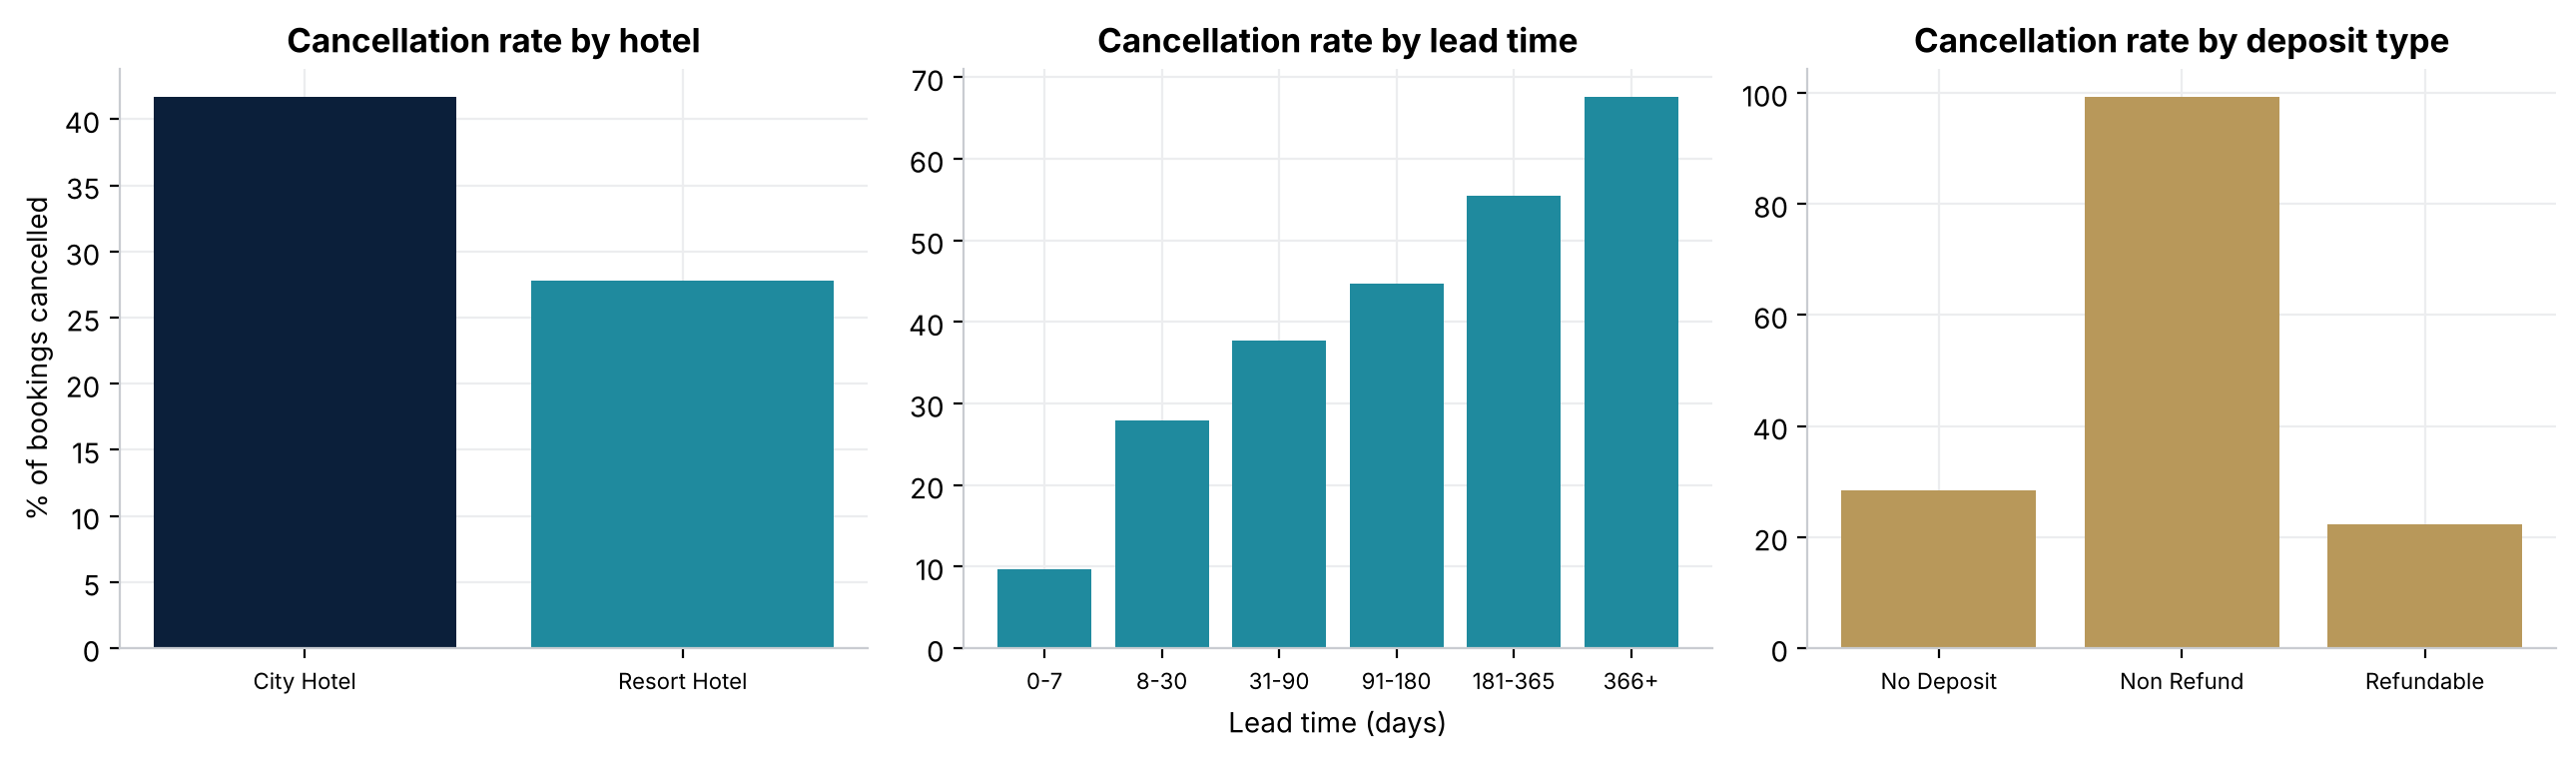

**Business interpretation.** 37.0% of bookings are cancelled - ignoring them would overstate demand by about a third. Cancellation climbs from 10% for last-minute bookings to 68% beyond a year of lead time, and 'Non Refund' deposits cancel at 99% (implausibly high, so it likely reflects how the source system recorded these bookings; deposit type is not used). This is why the model counts bookings 'on the books' at the origin only if not yet cancelled by then.

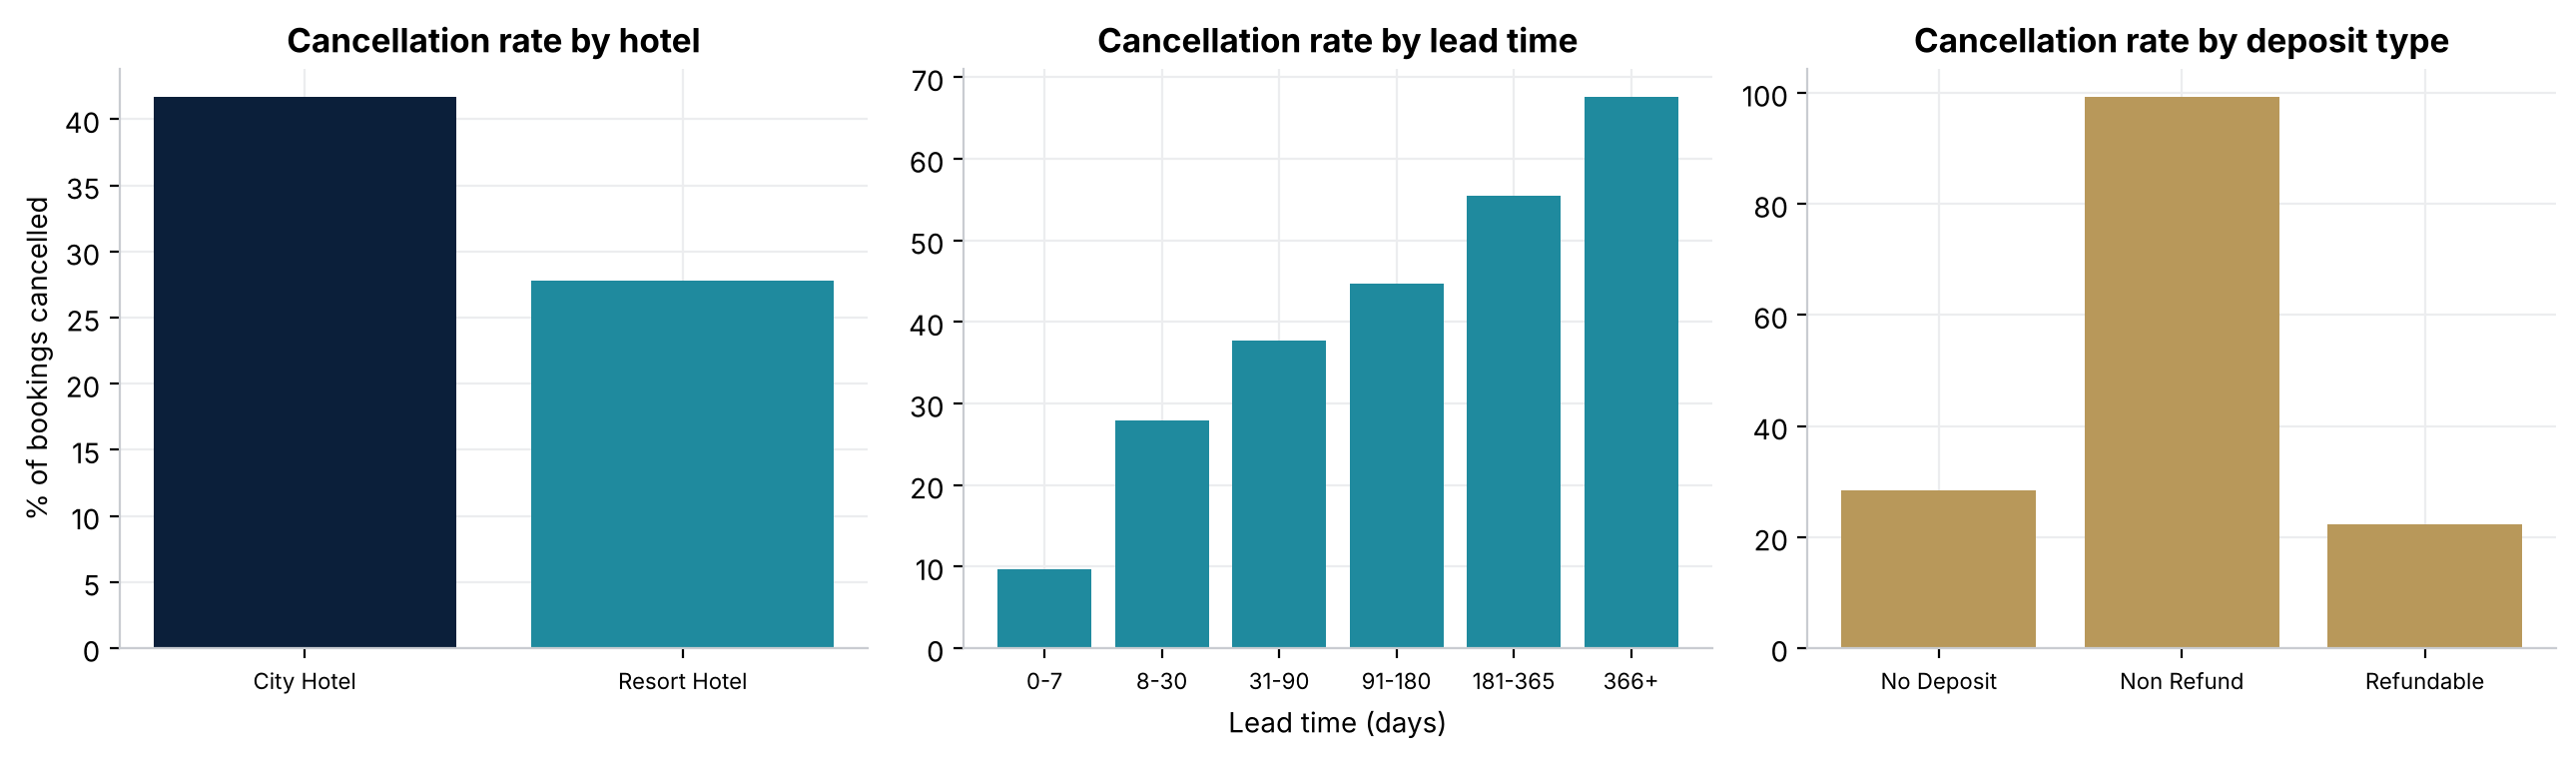

In [5]:
show('cancellation')

## 5. Arrival dates and date coverage

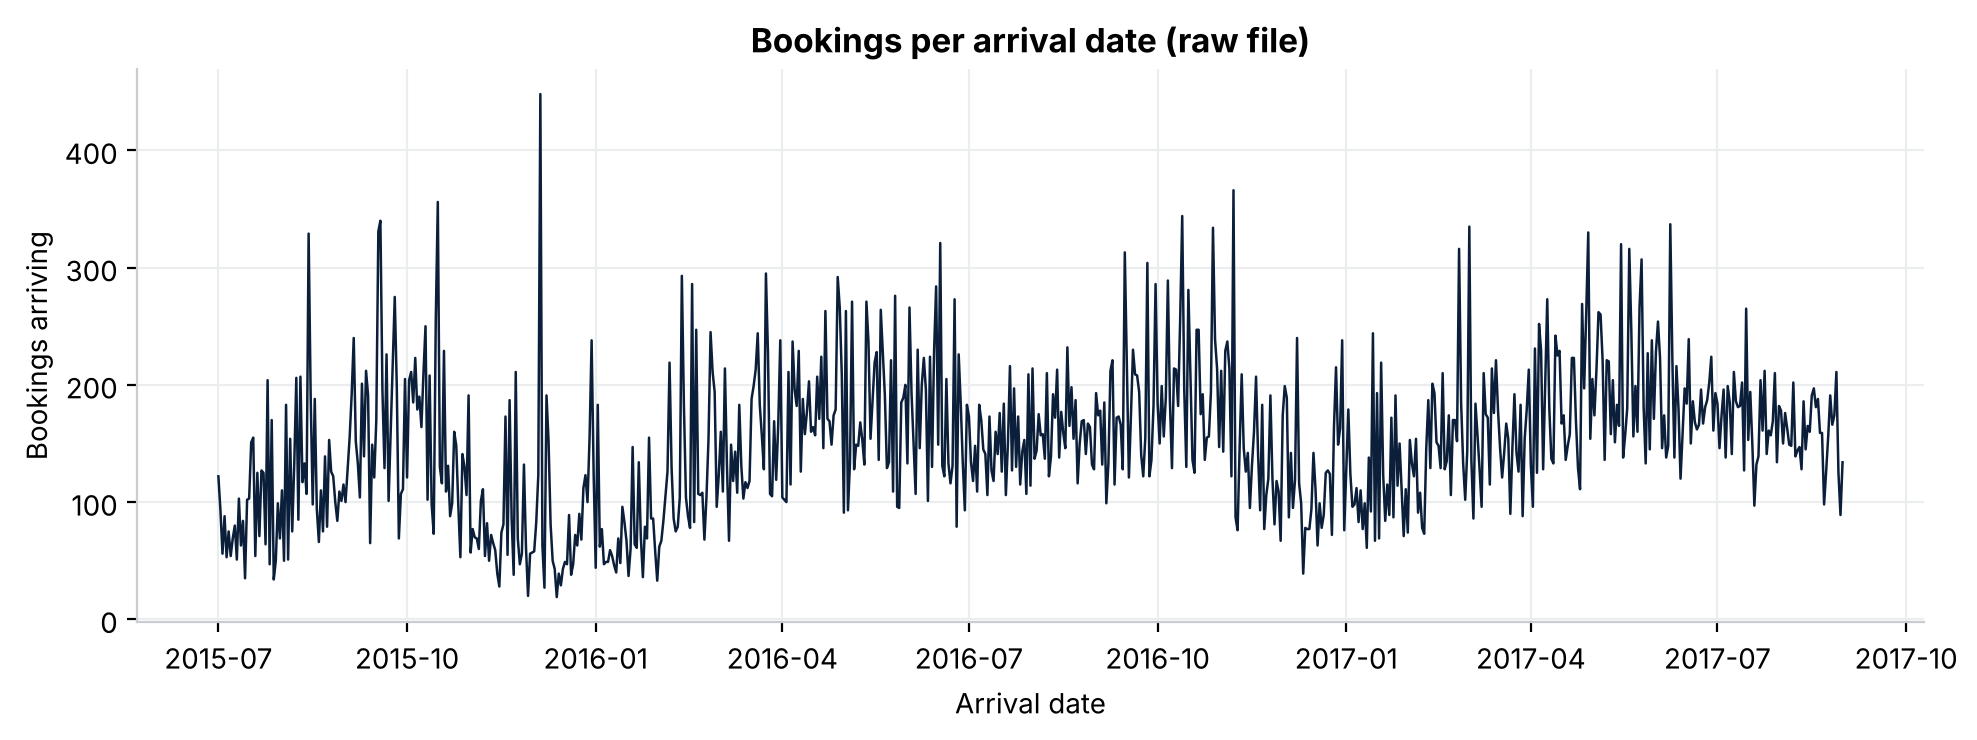

**Business interpretation.** Arrivals span 2015-07-01 to 2017-08-31 (793 consecutive days, no gaps). Volume peaks in summer (max 448 arrivals/day) and troughs in winter; 2015 and 2017 are partial years, so the data holds only two full summers (2016, 2017) plus July-August 2015 - a key limit for learning seasonality.

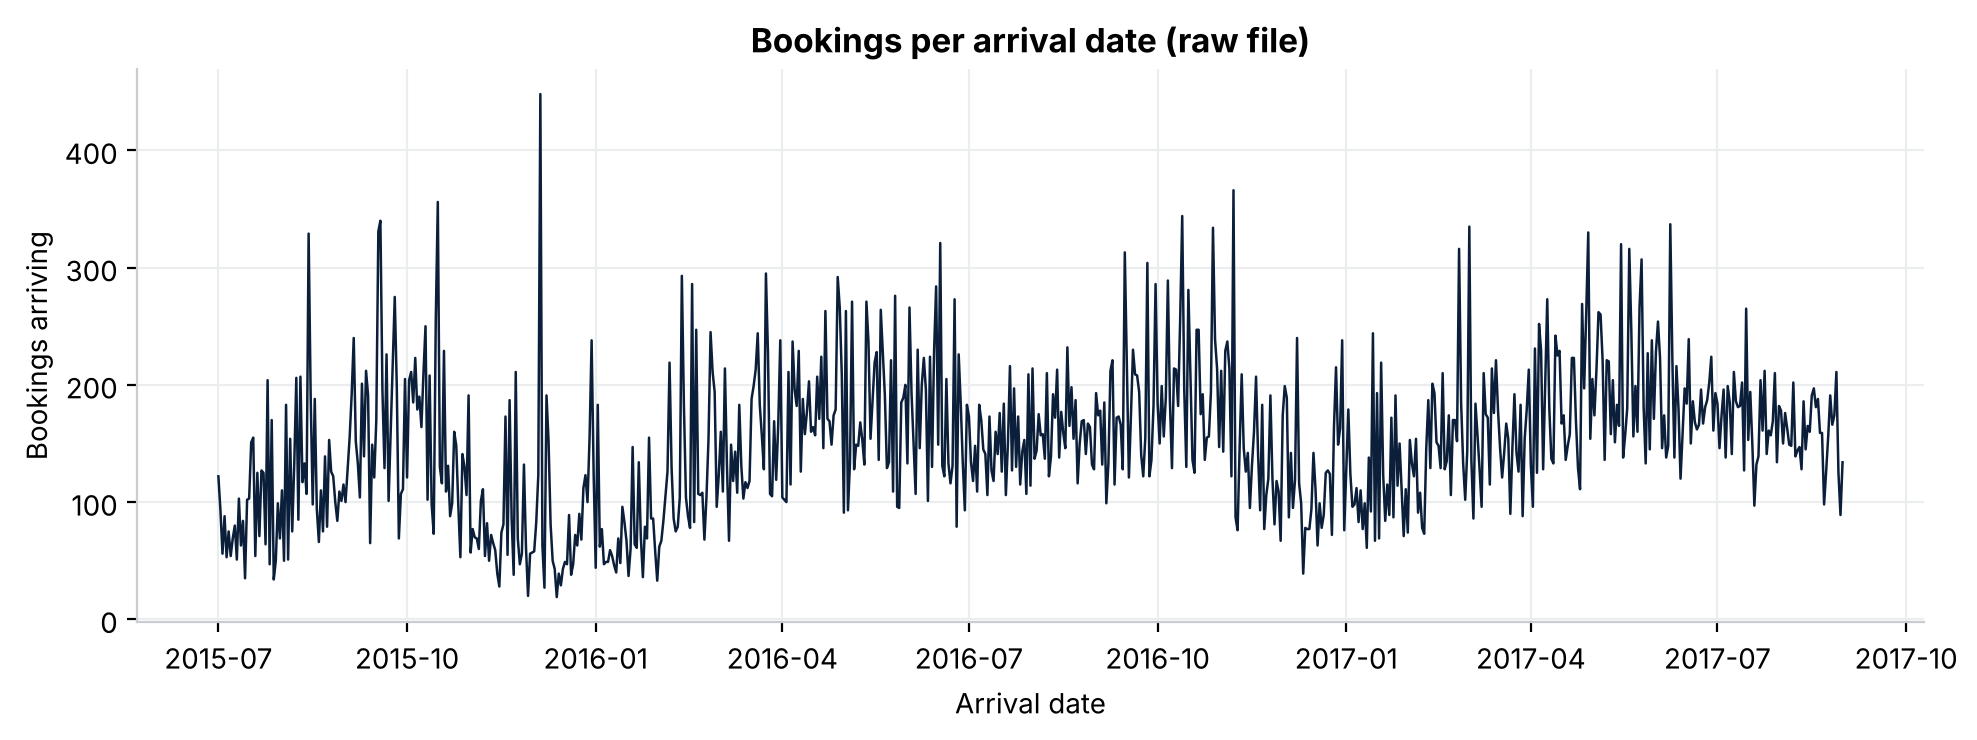

In [6]:
show('arrival_distribution')

## 6. Weekday vs weekend

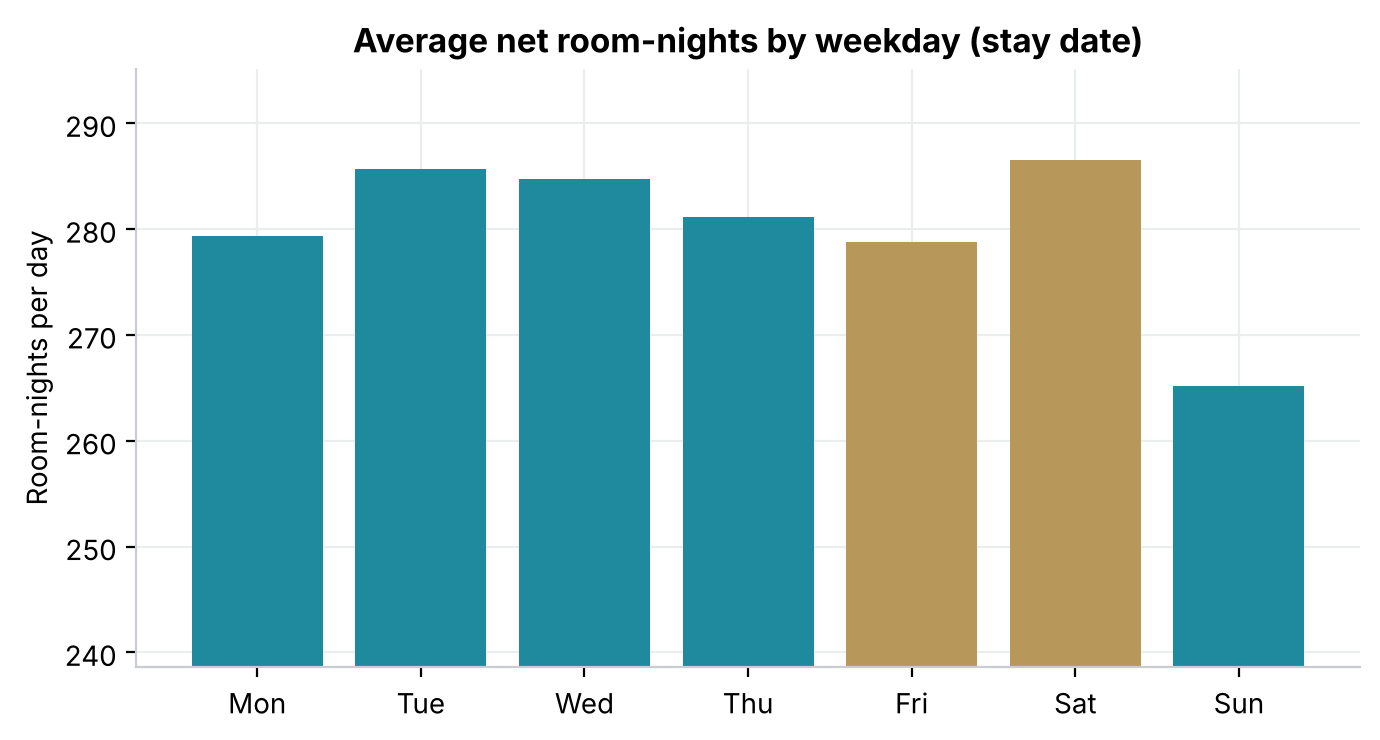

**Business interpretation.** Sat is the busiest night and Sun the quietest; weekend nights average -2.2% versus weekdays. The weekday pattern is modest but consistent, which is exactly what the seasonal-naive baseline exploits.

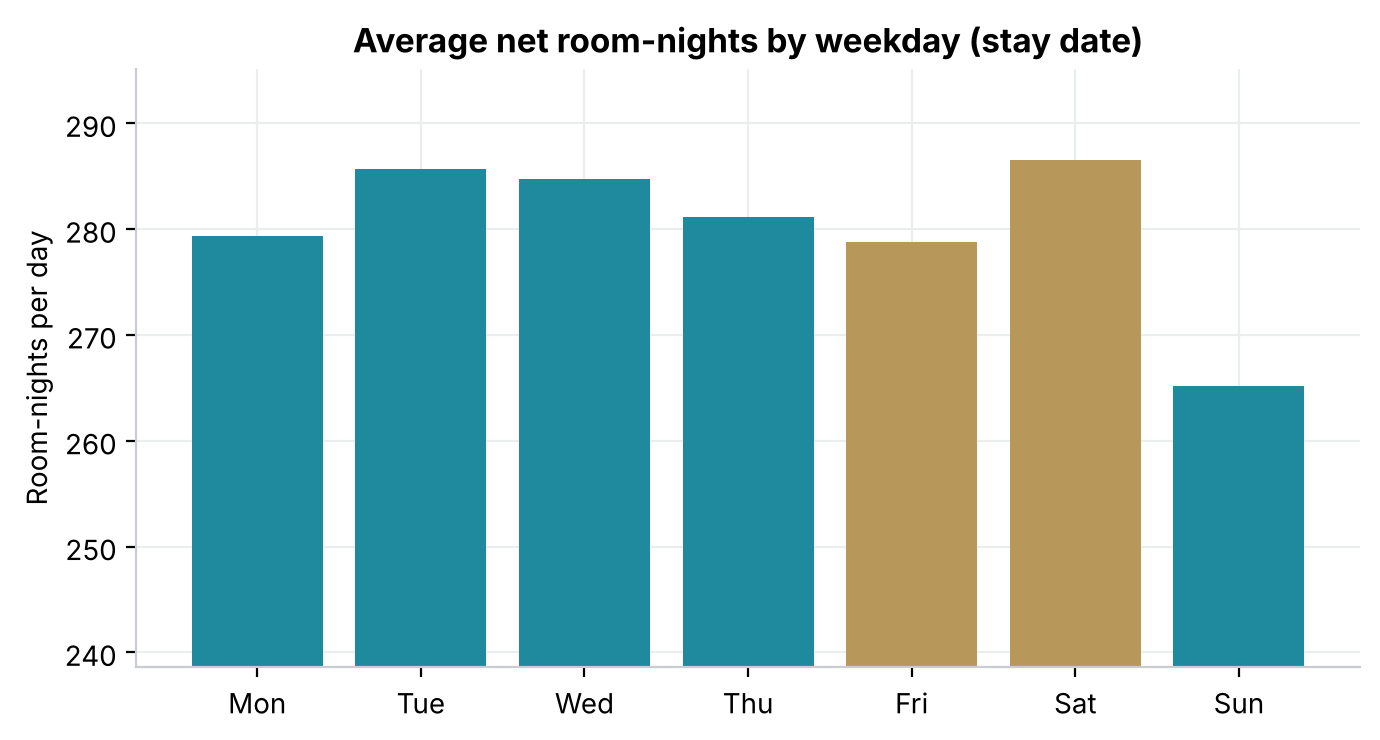

In [7]:
show('weekday_pattern')

## 7. Monthly trends and seasonality

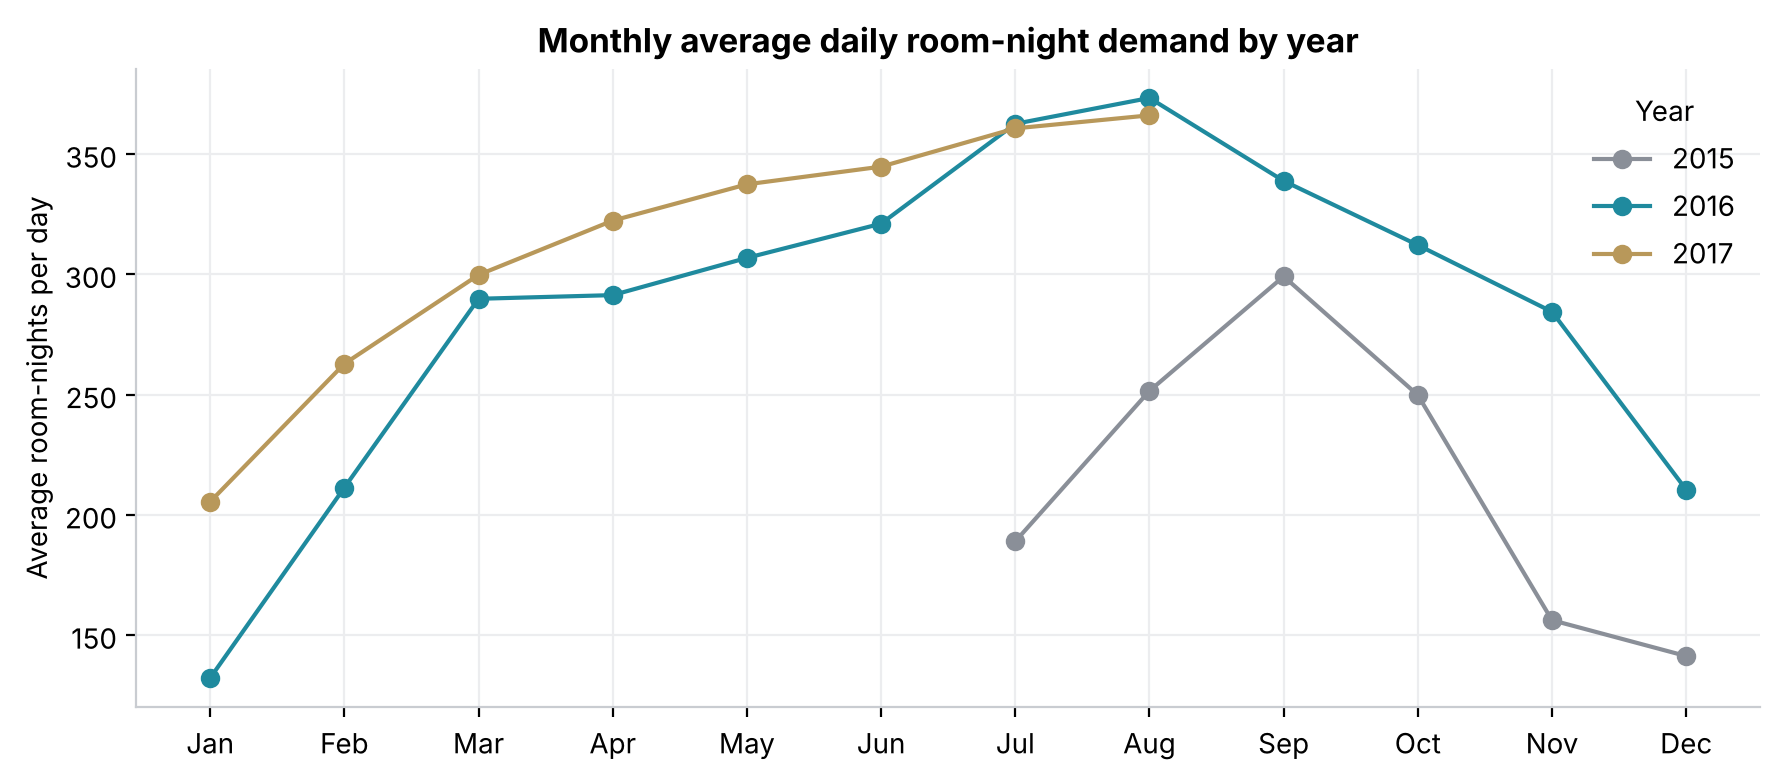

**Business interpretation.** Demand peaks in Jun and bottoms out in winter. Comparing Jan-Aug, 2017 averages +9.2% versus 2016 (2015 has July-December only), so there is a level shift on top of the seasonal cycle - a plain 'same as last year' rule would be biased.

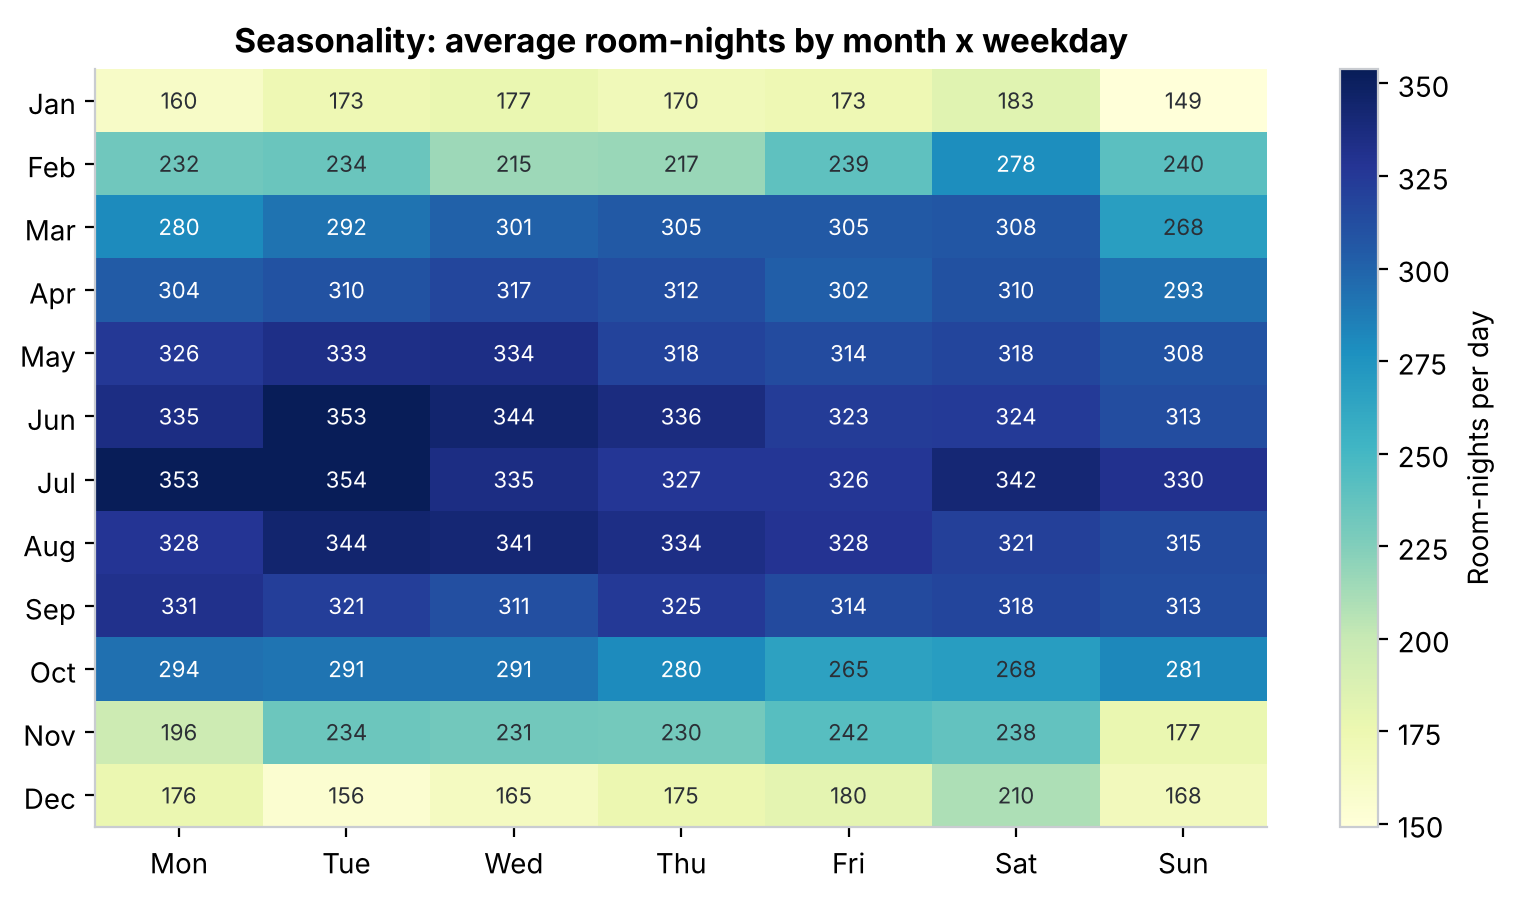

**Business interpretation.** Month matters more than weekday: Jun-Aug averages 1.7x Dec-Feb, while the busiest weekday in a month is on average only 17% above the quietest. Calendar features therefore set the level, and recent history + bookings on the books supply the day-level detail.

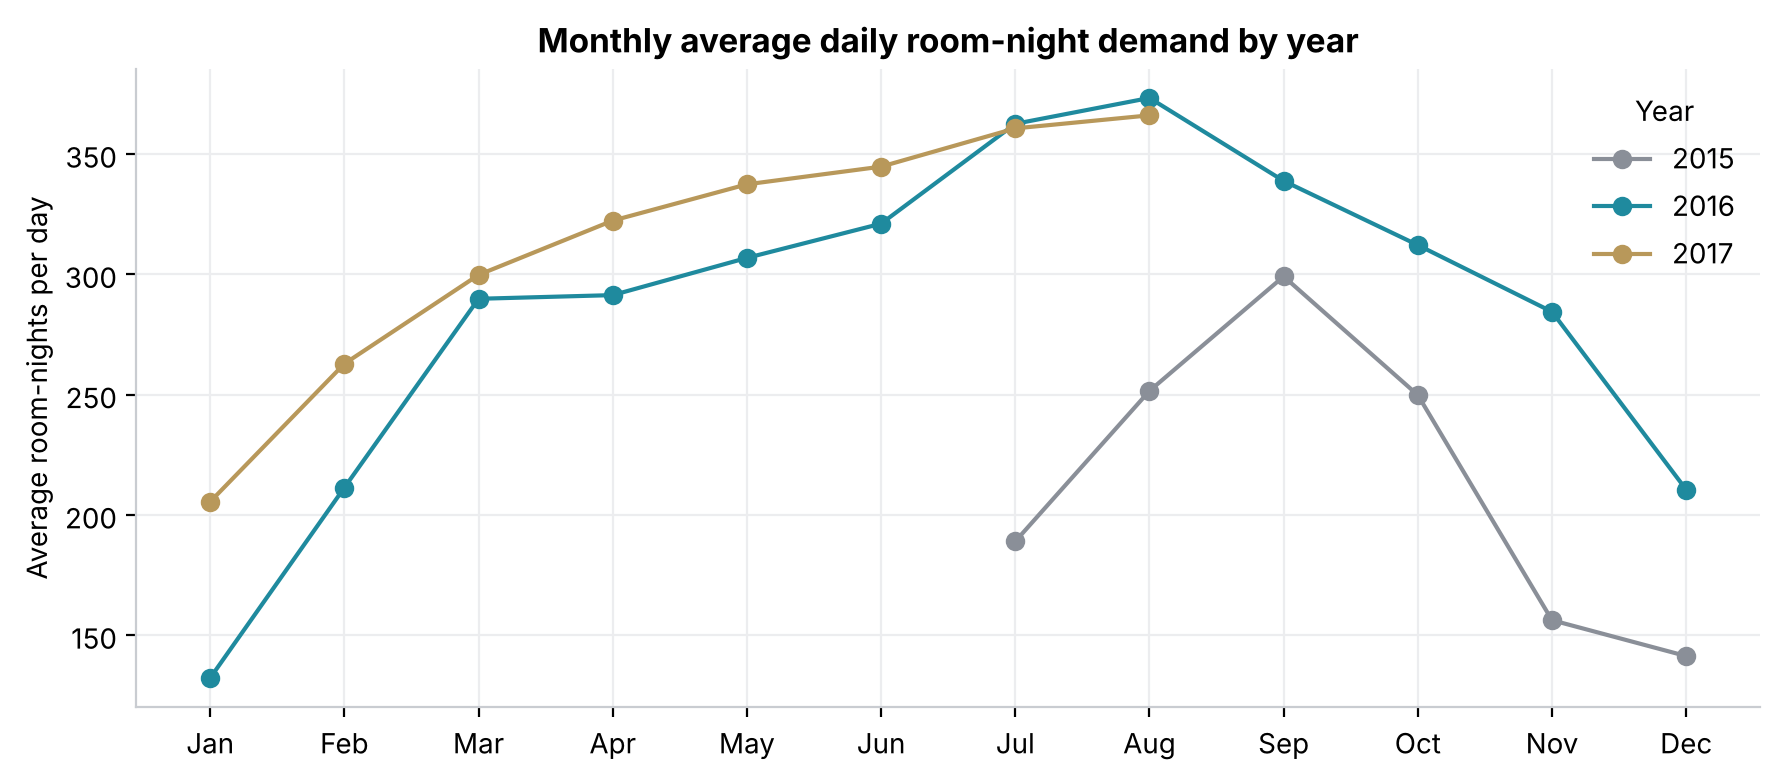

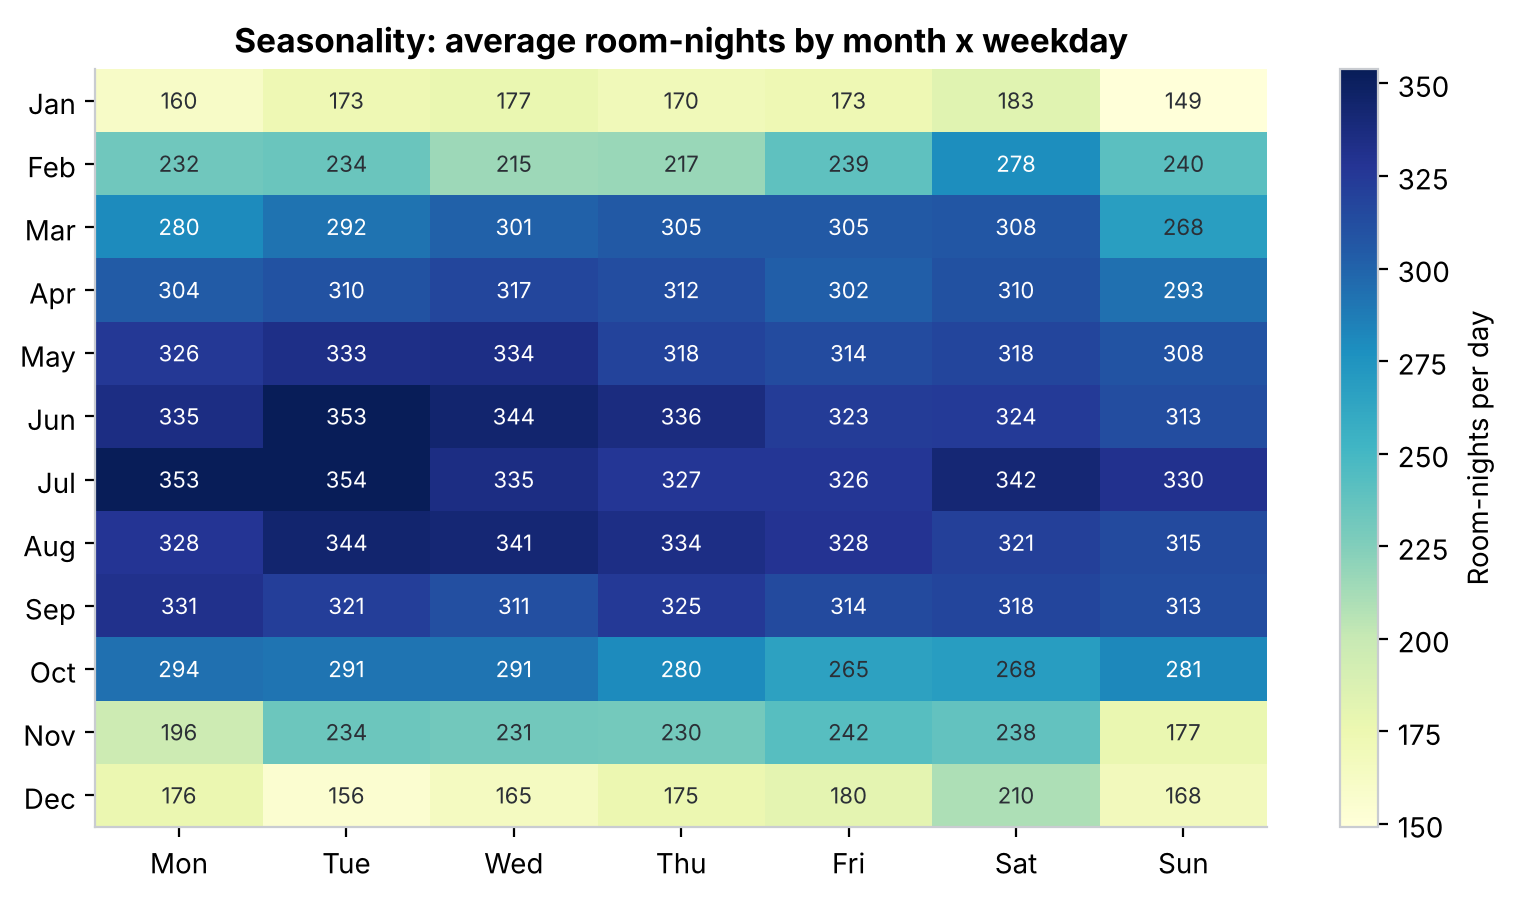

In [8]:
show('monthly_trend'); show('seasonality_heatmap')

## 8. Room categories (reserved vs assigned)

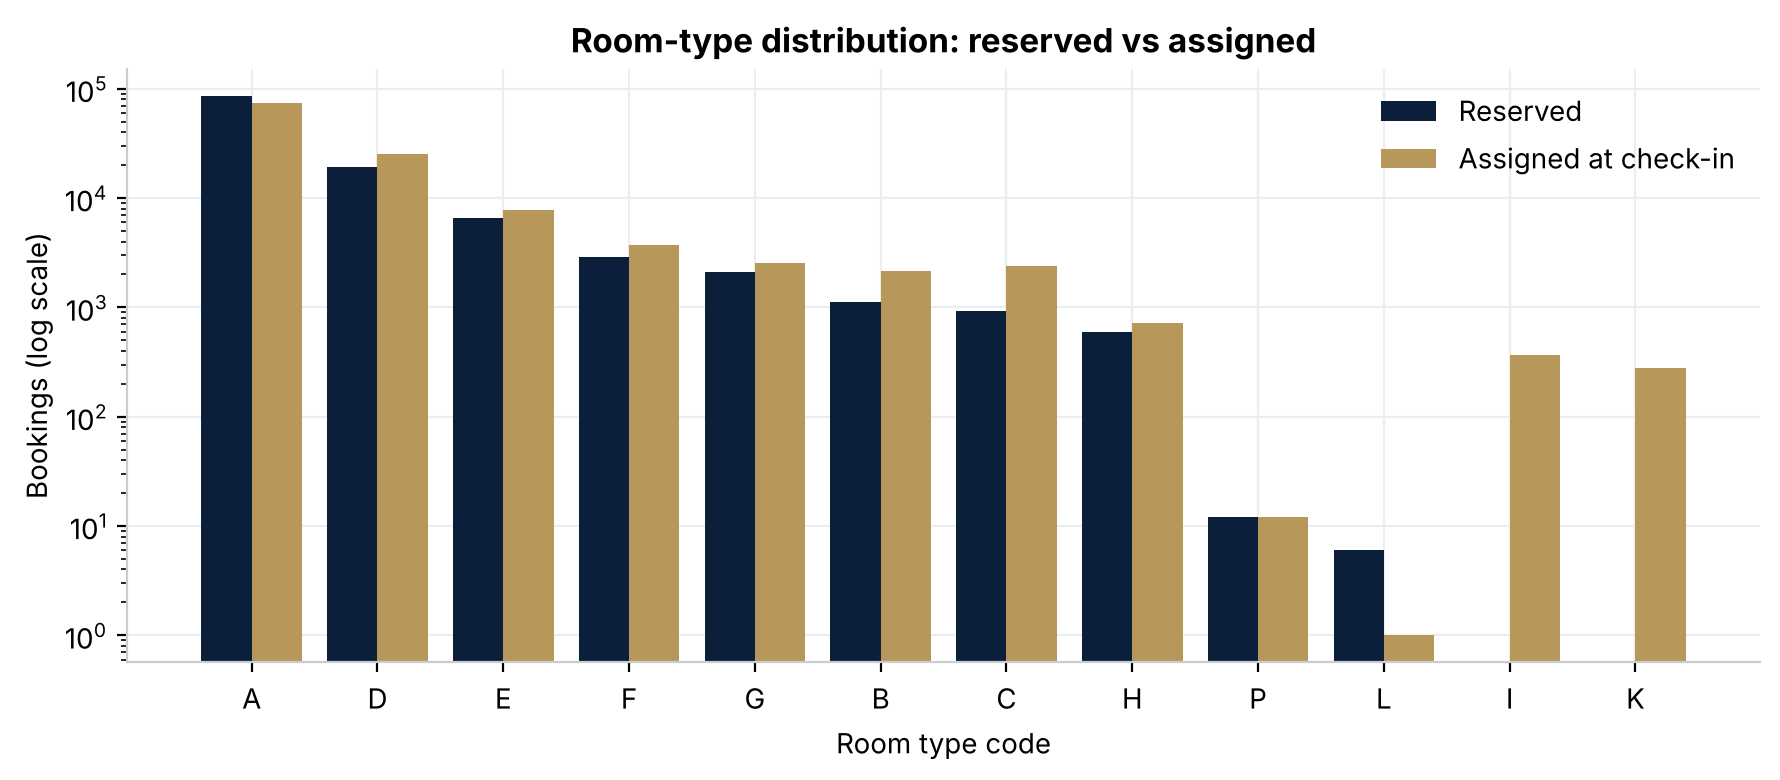

**Business interpretation.** Type A holds 72% of reservations. 12.5% of guests are placed in a different type from the one reserved, and assigned types I and K never appear as reservations - so assigned type is a check-in outcome. We forecast by RESERVED type and pool the rare types B, C, H, L, P into 'Other'.

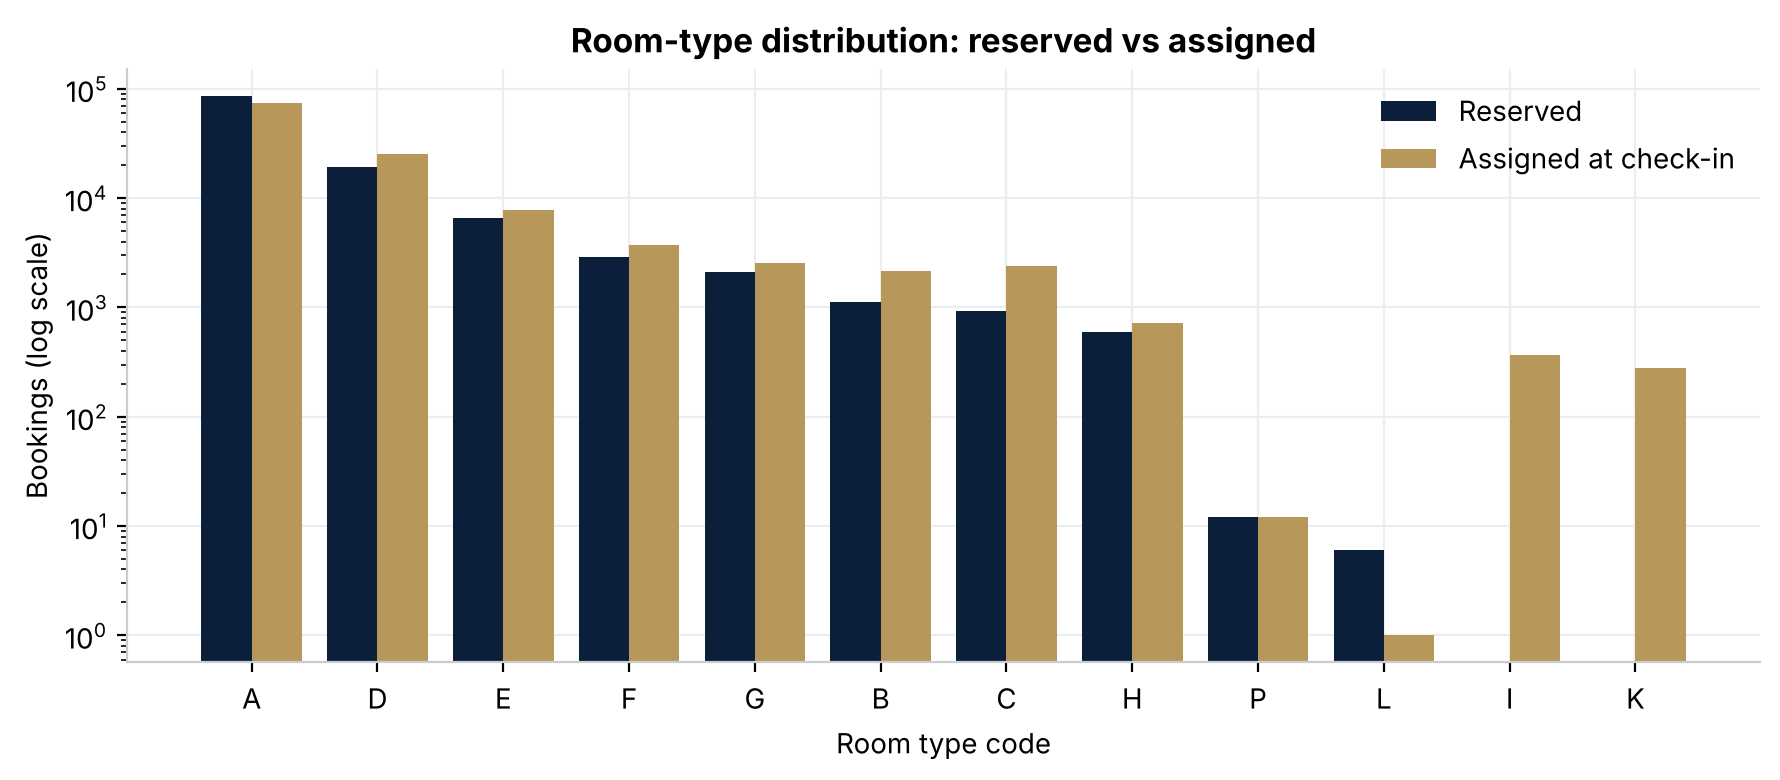

In [9]:
show('room_categories')

## 9. Lead time

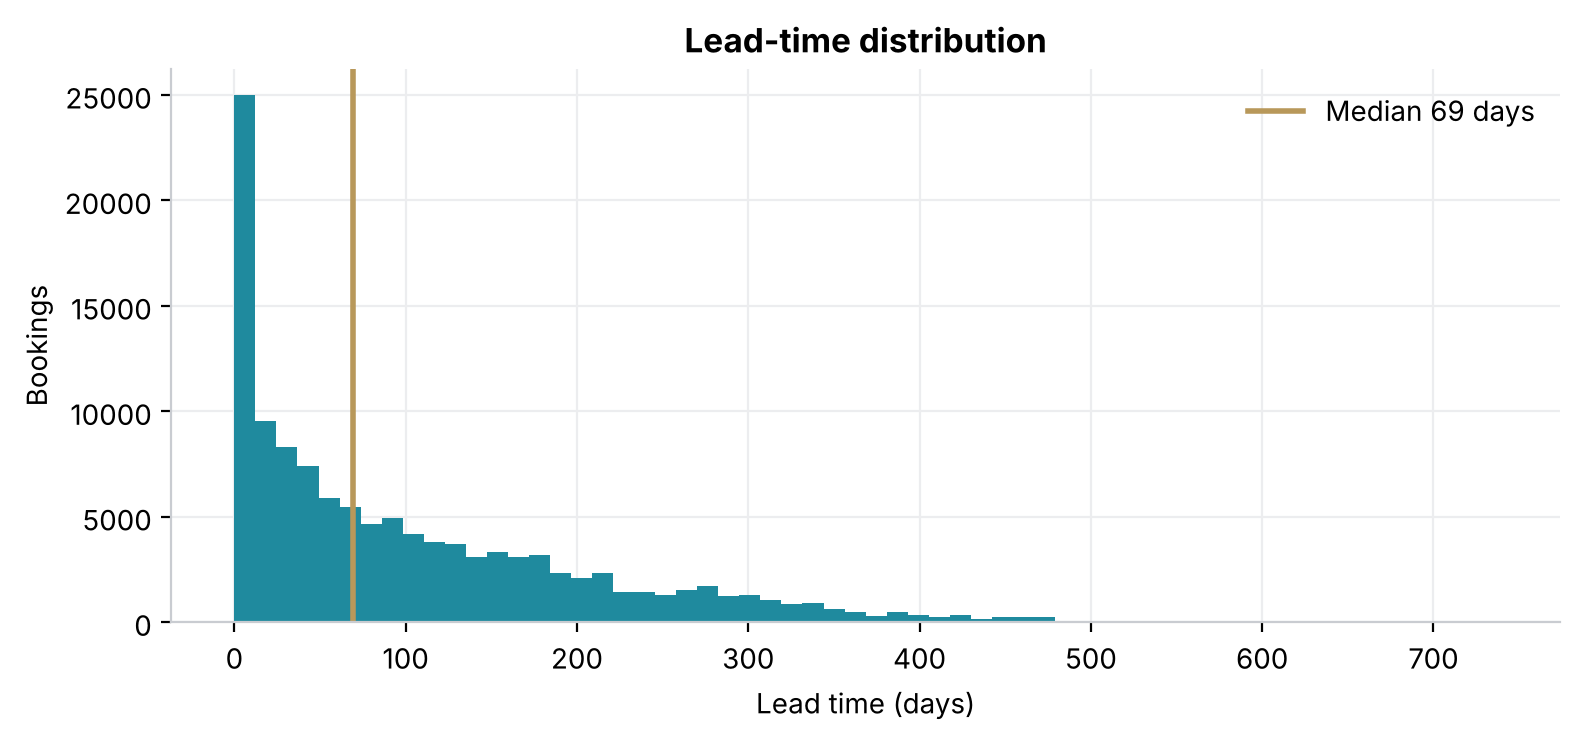

**Business interpretation.** Median lead time is 69 days but the mean is 104: a long right tail (max 737) of very early bookings. 43% of bookings are made more than 90 days ahead, which is what makes 'on-the-books' counts informative 7-14 days out.

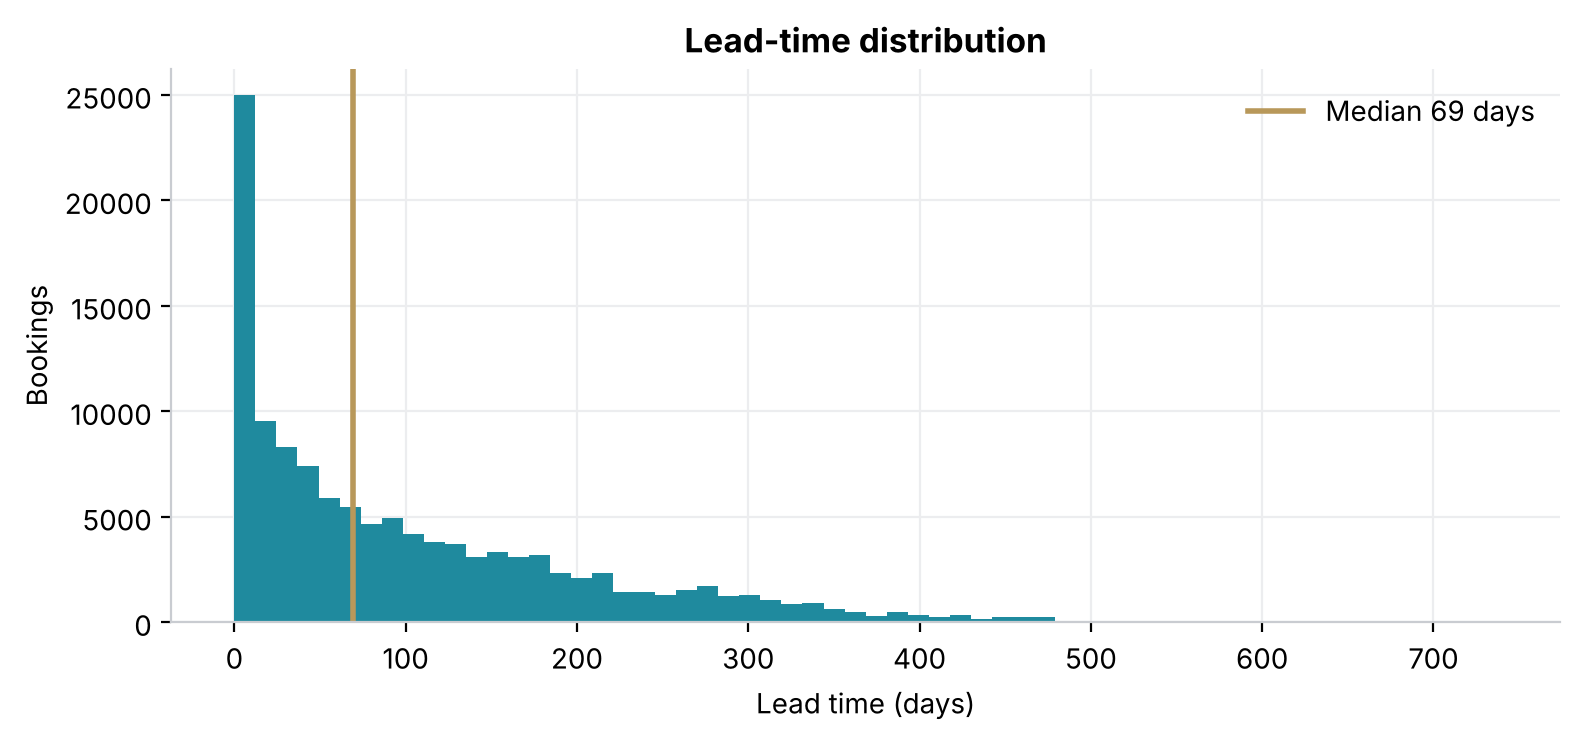

In [10]:
show('lead_time')

## 10. Average daily rate

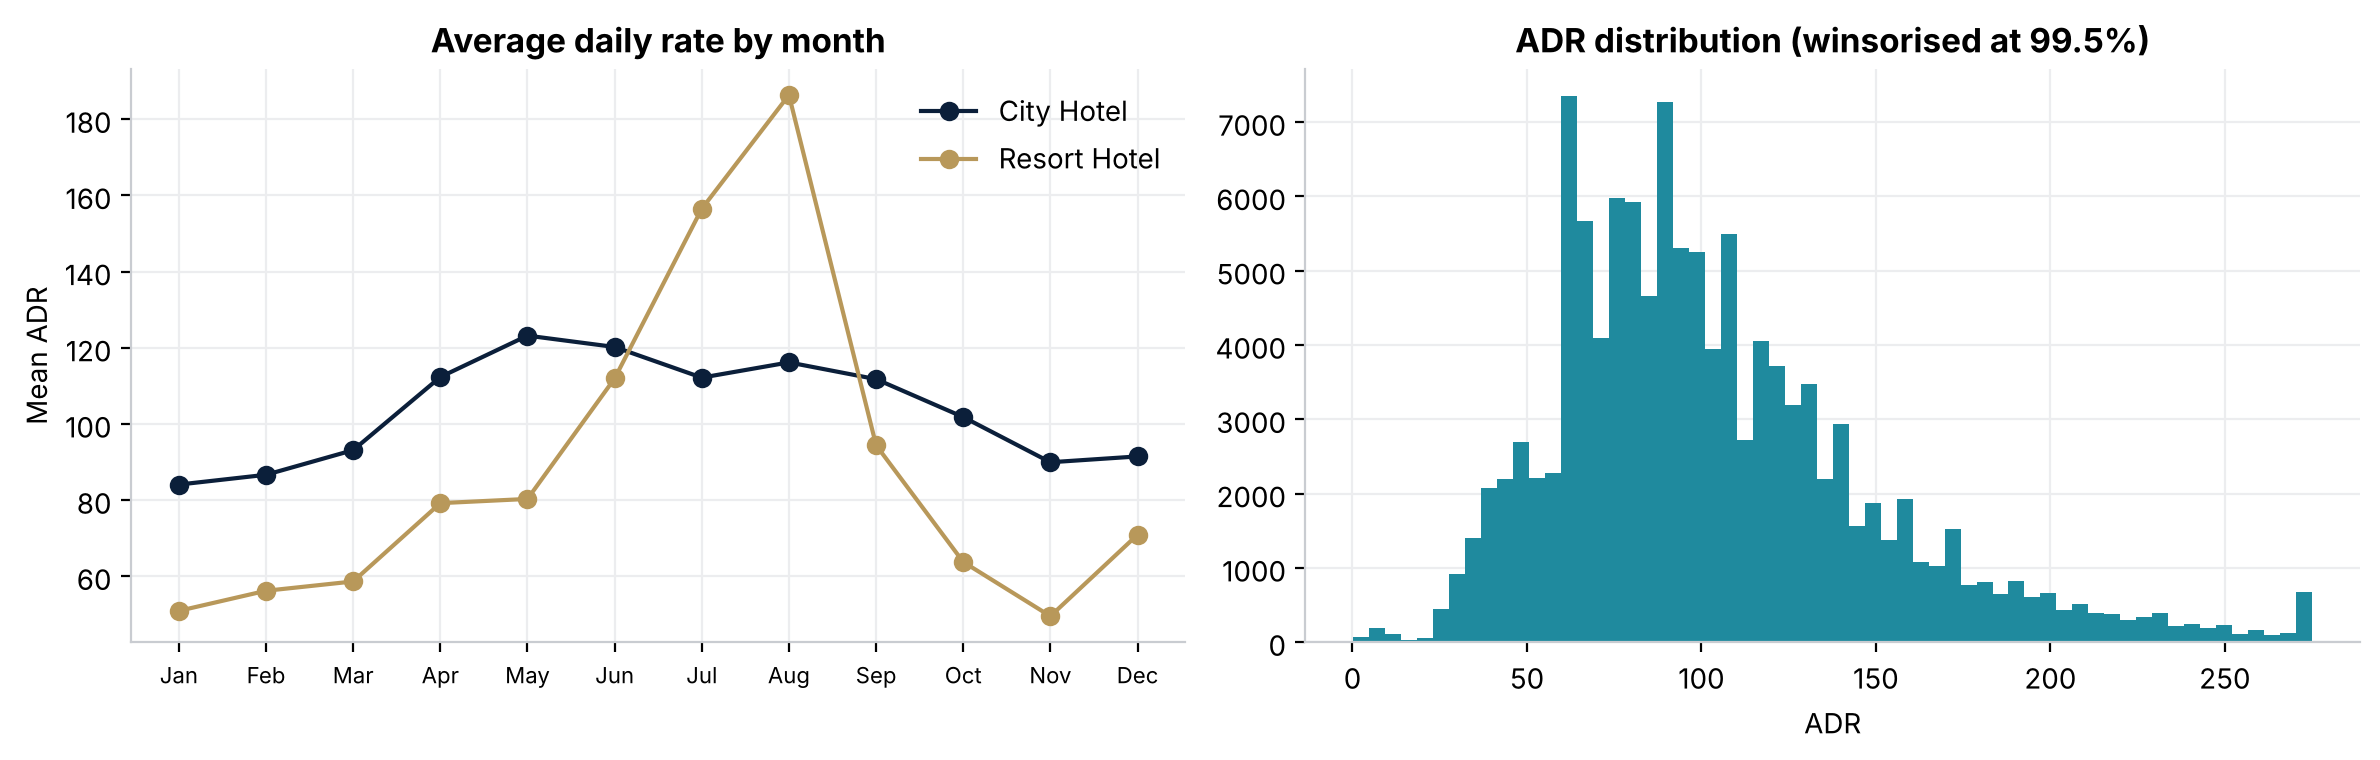

**Business interpretation.** Price follows demand: mean ADR is highest in Aug (141) and lowest in Jan (72), with the Resort Hotel far more seasonal than the City Hotel. 1,959 raw rows have ADR = 0 and one has 5,400 (excluded from the chart tail); ADR is not a model feature because it is only observed with the booking, not forecastable demand.

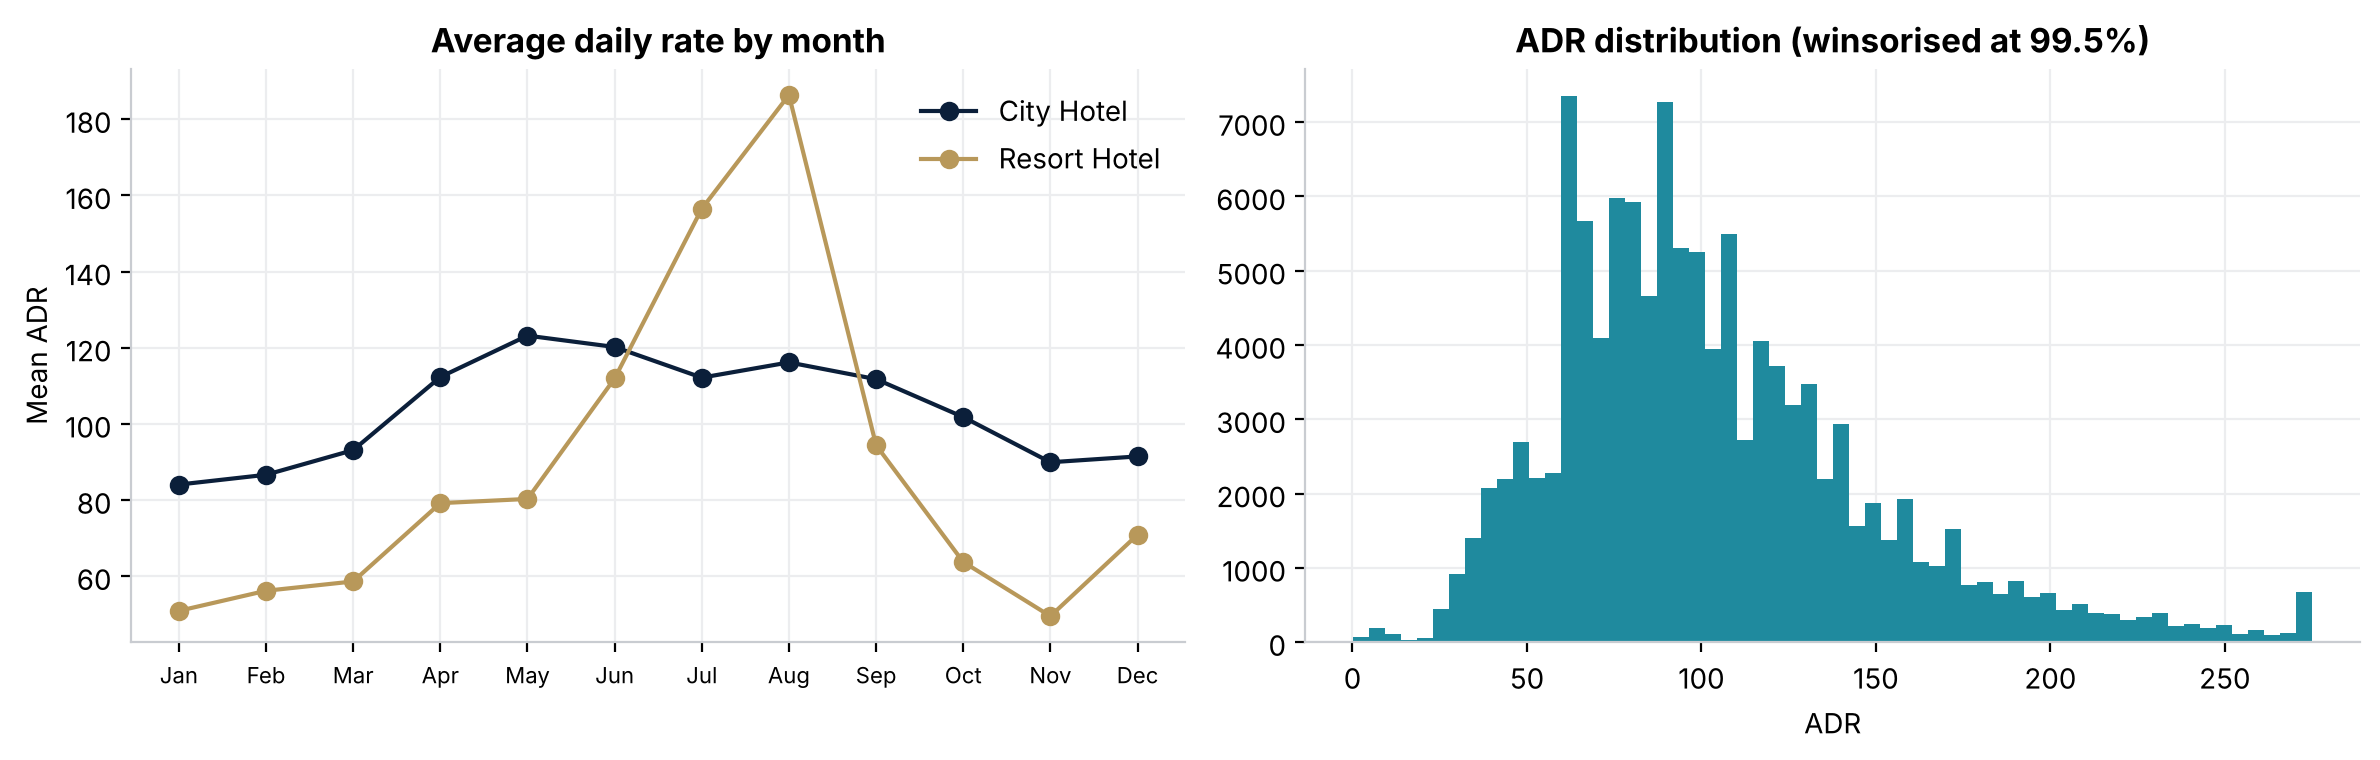

In [11]:
show('adr')

## 11. Correlation

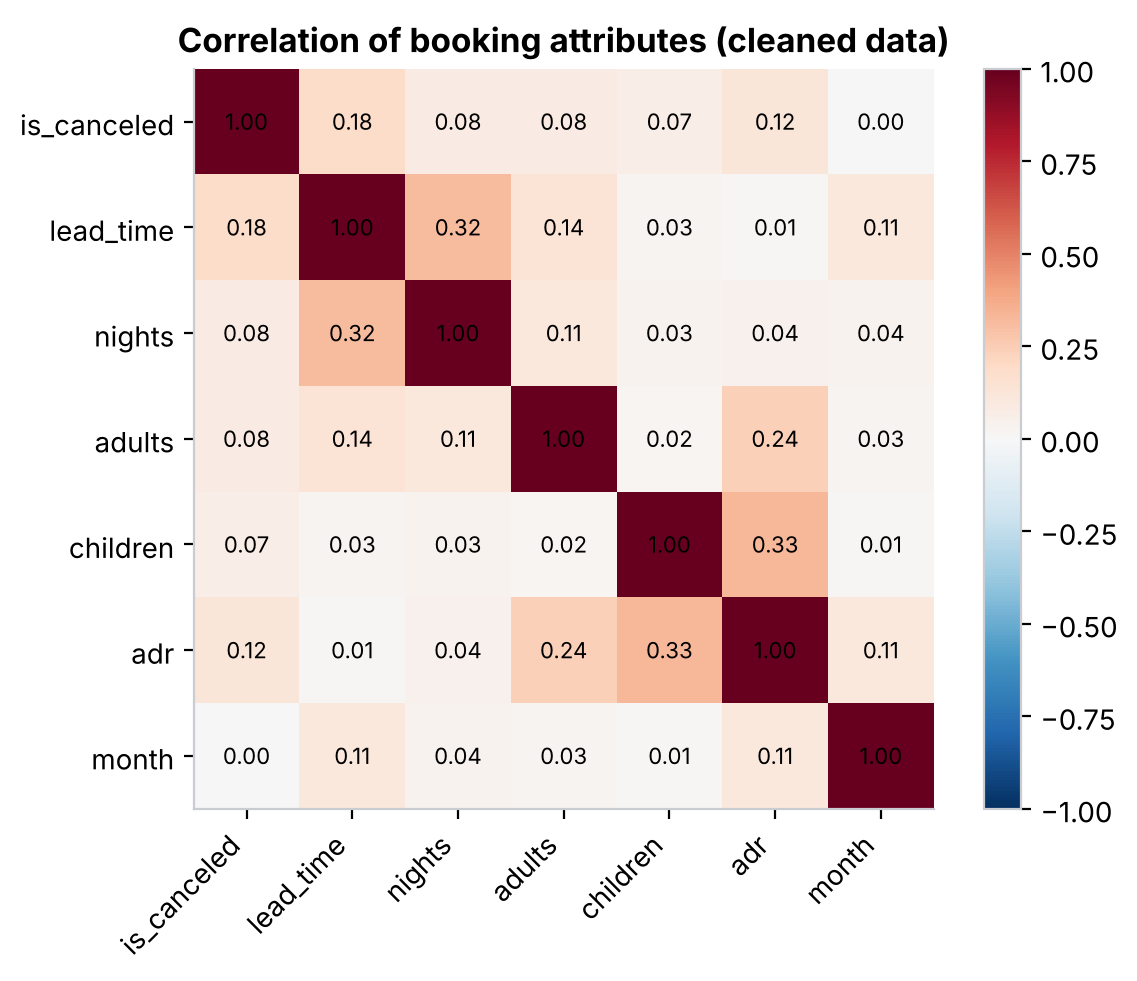

**Business interpretation.** lead_time is the attribute most correlated with cancellation (r = 0.18); ADR vs month r = 0.11. These are booking-level attributes. For forecasting we correlate demand with its own history instead (see the lag features), and correlation is not used as causal evidence.

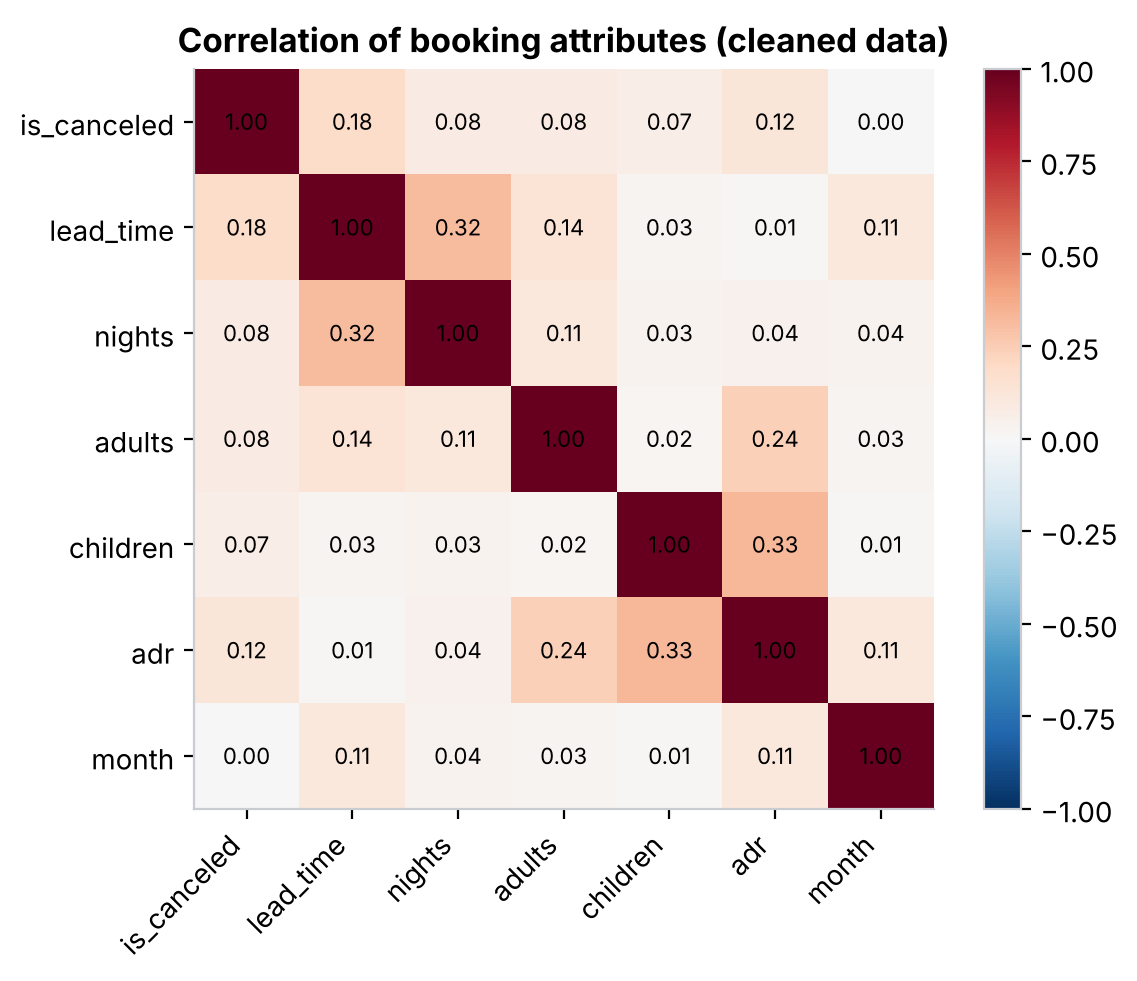

In [12]:
show('correlation')

## 12. Outliers

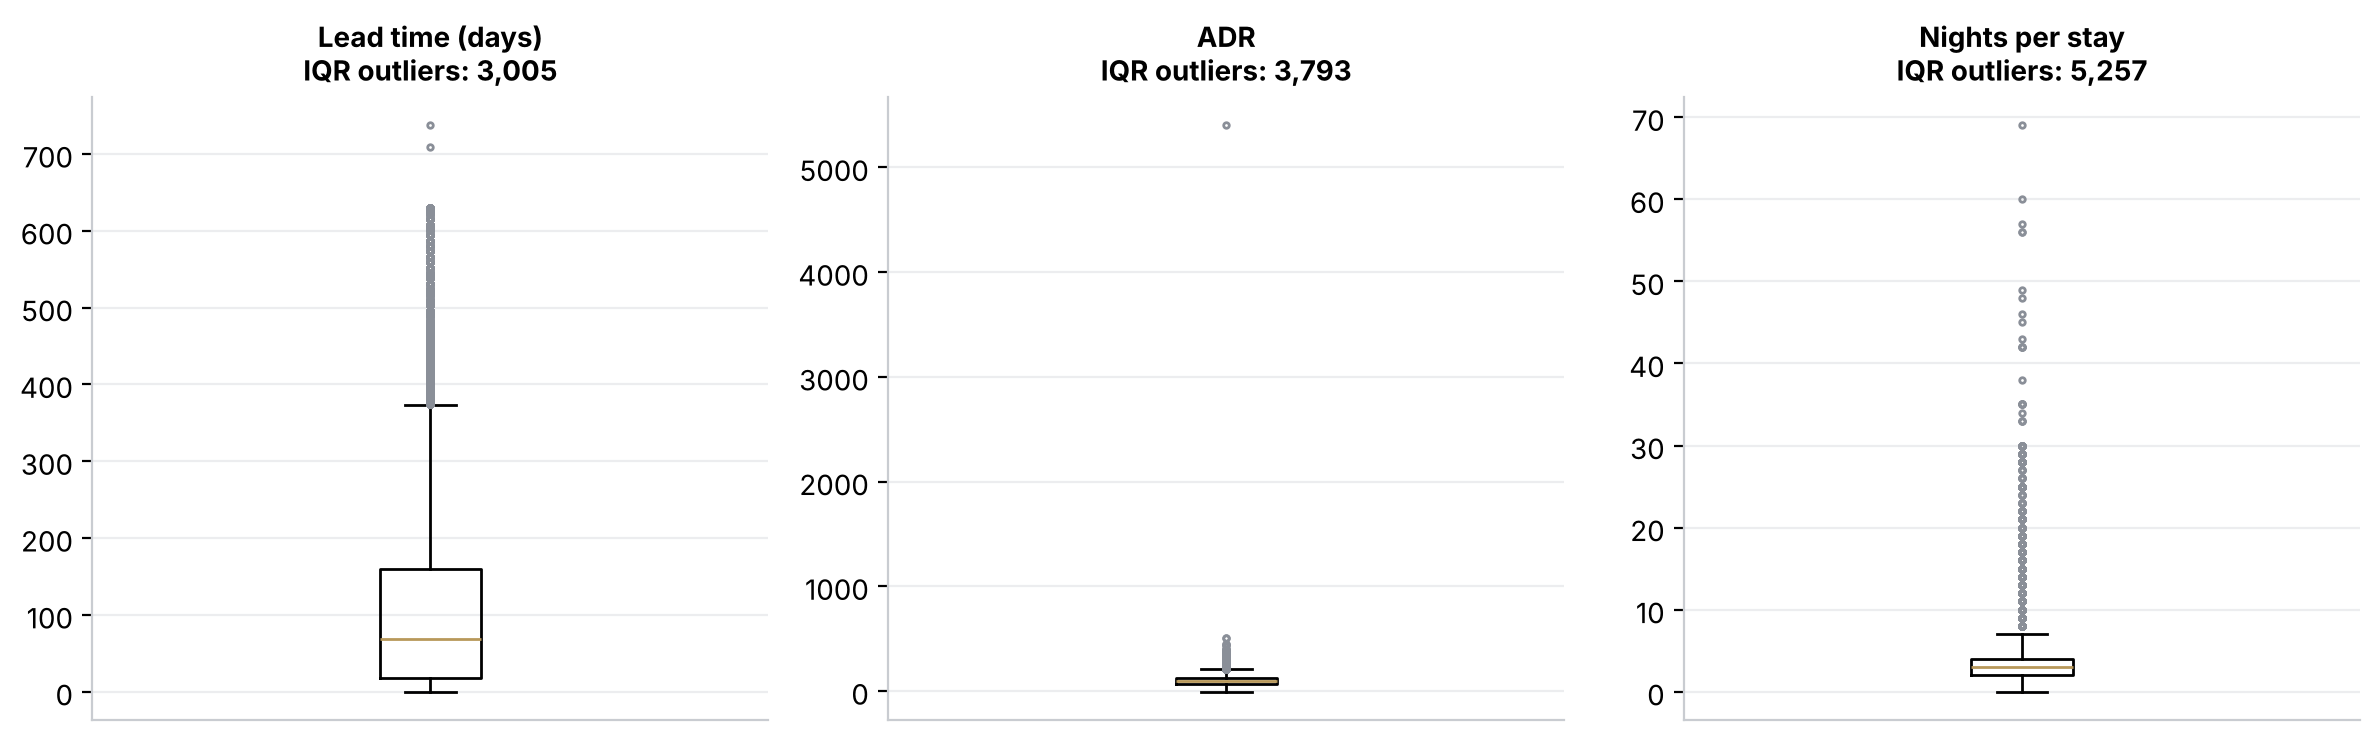

**Business interpretation.** Lead time, ADR and length of stay all have long right tails. ADR 5,400 and stays of 69 nights are extreme but still plausible bookings, so they are kept; they affect room-night counts by at most a handful of rows. Hard errors (zero nights, zero guests, negative ADR) are removed instead. See reports/cleaning_report.json.

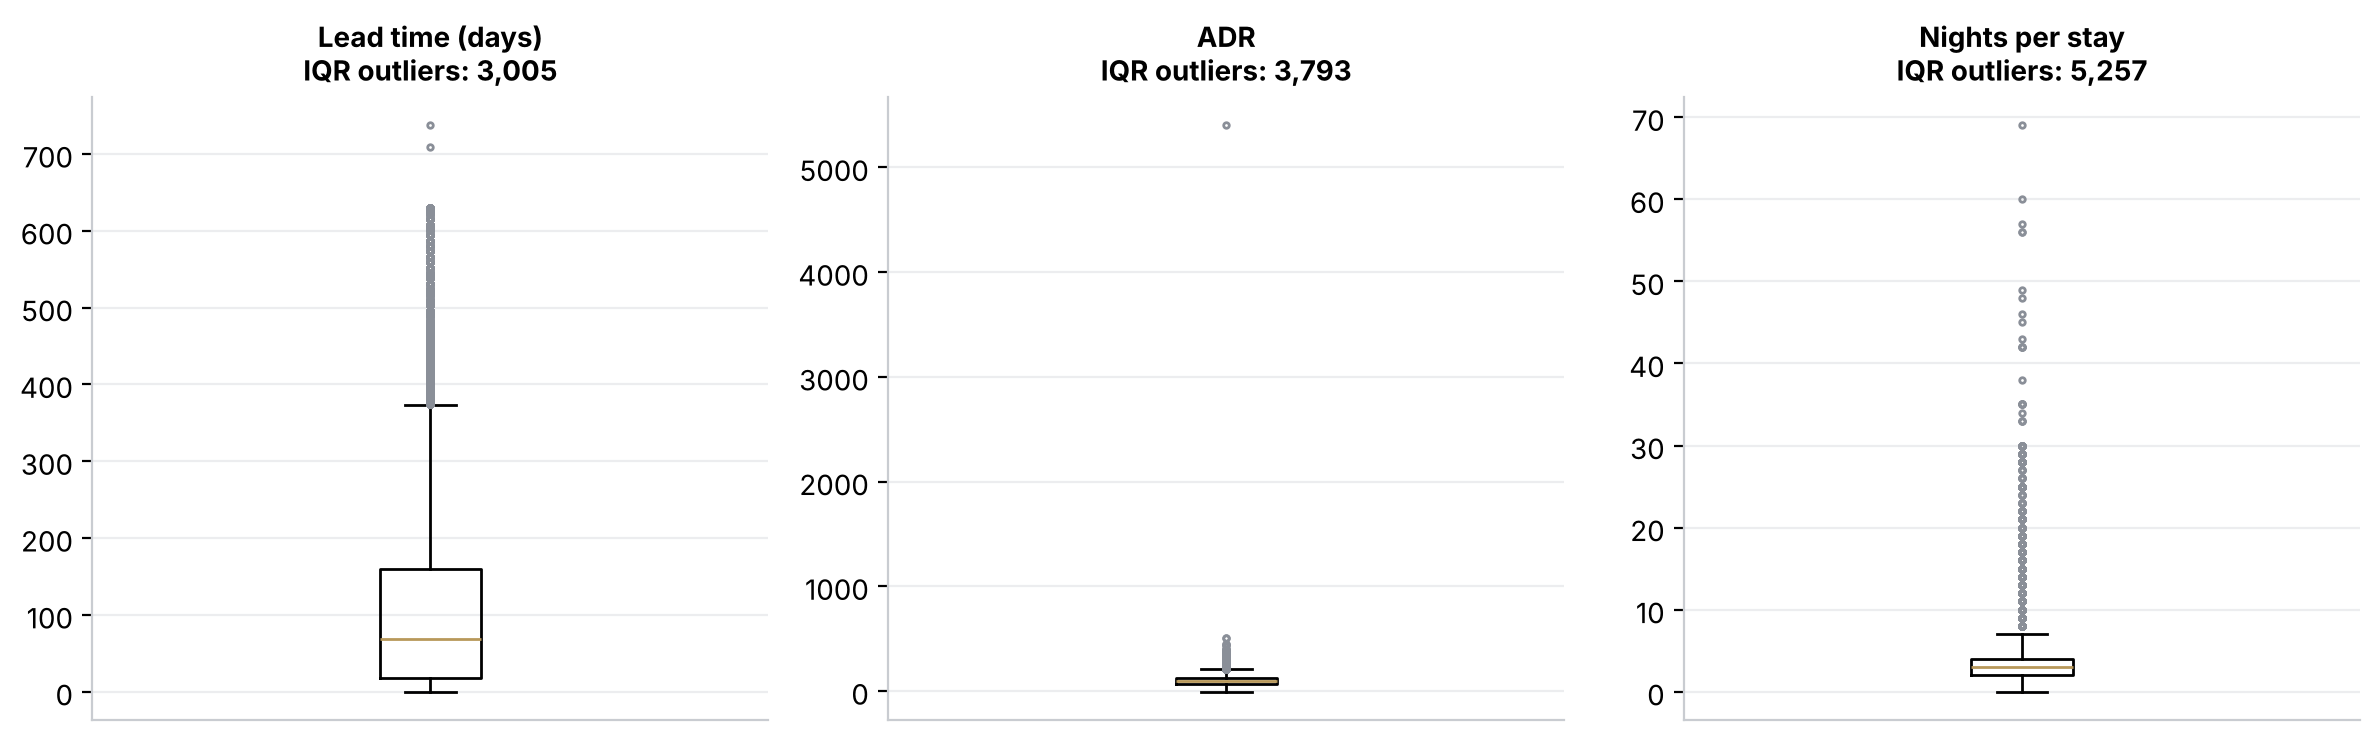

In [13]:
show('outliers')

## 13. Cleaning decisions (reproducible: `python -m src.preprocessing`)

In [14]:
rep = json.load(open(config.CLEAN_REPORT_FILE))
print({k: v for k, v in rep.items() if k != 'decisions'})
print(*rep['decisions'], sep='\n- ')

{'raw_rows': 119390, 'exact_duplicates_dropped': 31994, 'invalid_rows_dropped': {'zero_night_stay': 651, 'zero_guests': 106, 'negative_adr': 1}, 'flags_not_dropped': {'cancel_date_before_booking_date': 0, 'cancel_date_after_arrival': 0, 'adr_zero_rows': 1052, 'adr_above_1000': 1, 'reserved_ne_assigned': 12660, 'missing_country_UNK': 442}, 'clean_rows': 86638, 'room_category_bookings': {'A': 56009, 'D': 17294, 'E': 6000, 'F': 2805, 'Other': 2495, 'G': 2035}}
Raw file is never modified; processed data is written separately.
- Exact duplicates (all 32 columns) dropped, first copy kept.
- Rows with zero nights, zero guests or negative ADR dropped as invalid.
- children NA -> 0; country 'NULL' -> 'UNK'; agent/company 'NULL' -> NaN (not used as features).
- Cancelled / no-show rows are KEPT: they matter for on-the-books features and cancellation analysis.
- Room category = RESERVED room type (assigned type is only known at check-in).
- Rare room types B, C, H, L, P pooled into 'Other'.
- ADR

## 14. Target construction
For each stay date *d* and reserved room category *c*:

`demand(d, c)` = number of booked room-nights on night *d* from bookings that were **not cancelled** (1 booking = 1 room, deduplicated).

* Booking-level rows are expanded to one row per night (`expand_to_stay_nights`).
* Cancelled / no-show bookings are **kept in the data**: they feed the *on-the-books* features and the cancellation analysis, but not the target.
* The first 21 days (stays that began before the file starts) are dropped as burn-in; nights after 2017-08-31 are excluded because later arrivals are missing.

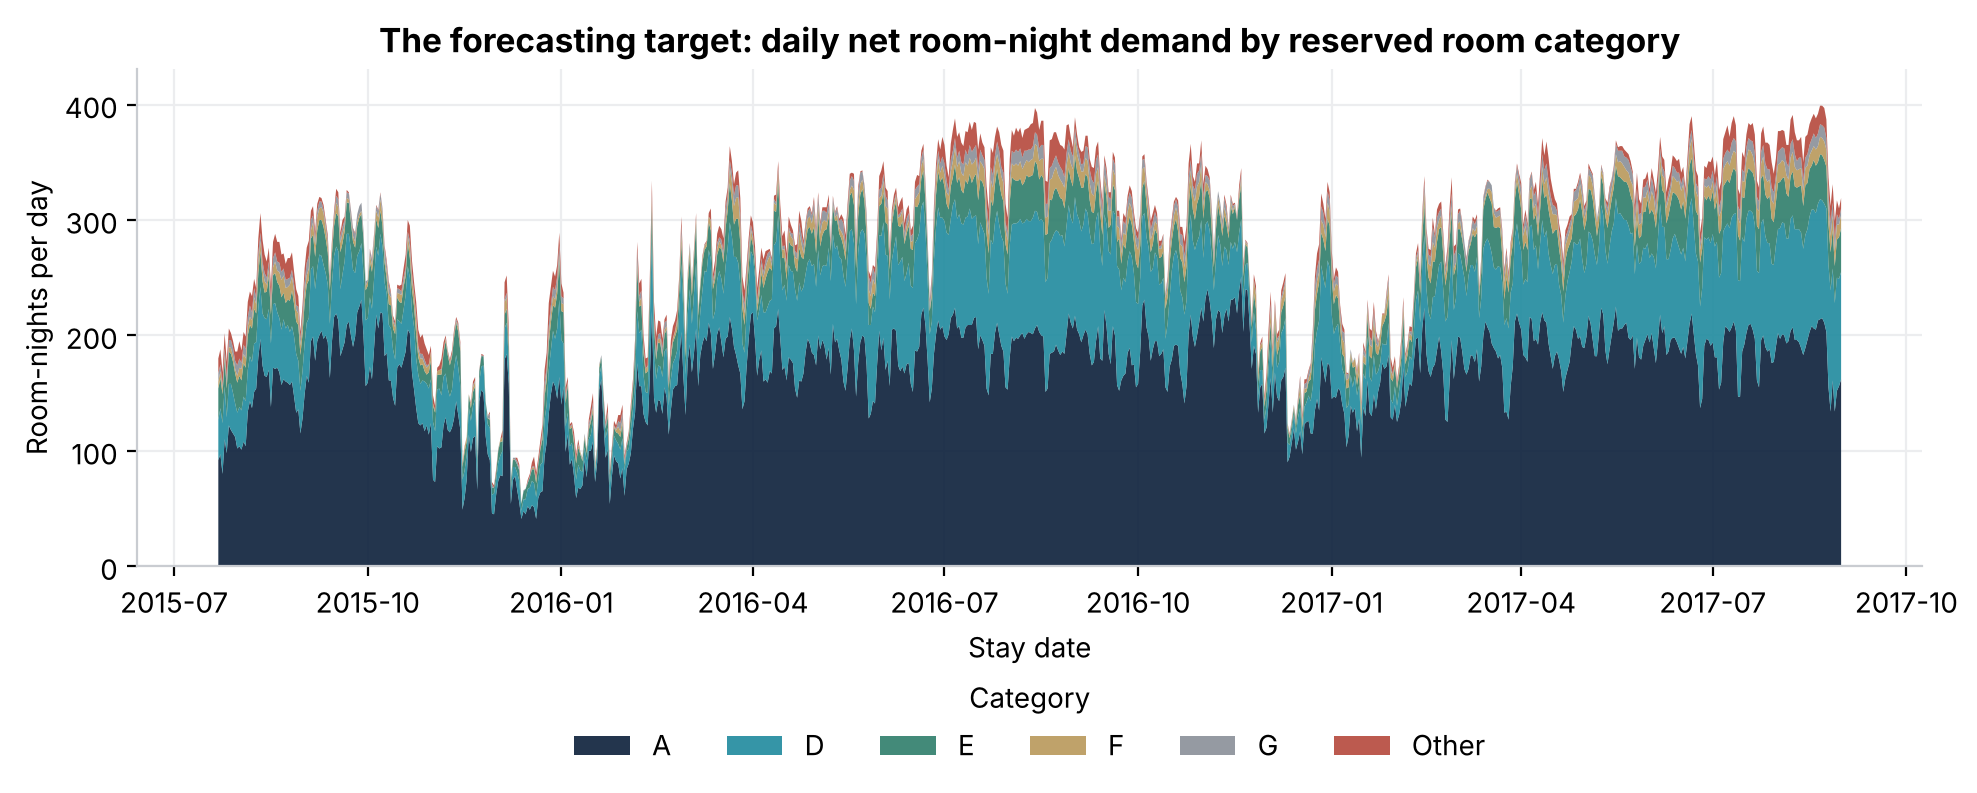

**Business interpretation.** Category A carries 60% of room-nights, D 23%, E 9%; F, G and Other are small (8% together), so their daily counts are noisy and will show the largest relative error. Target = room-nights on the stay date from bookings NOT cancelled; this is booking demand, not physical occupancy.

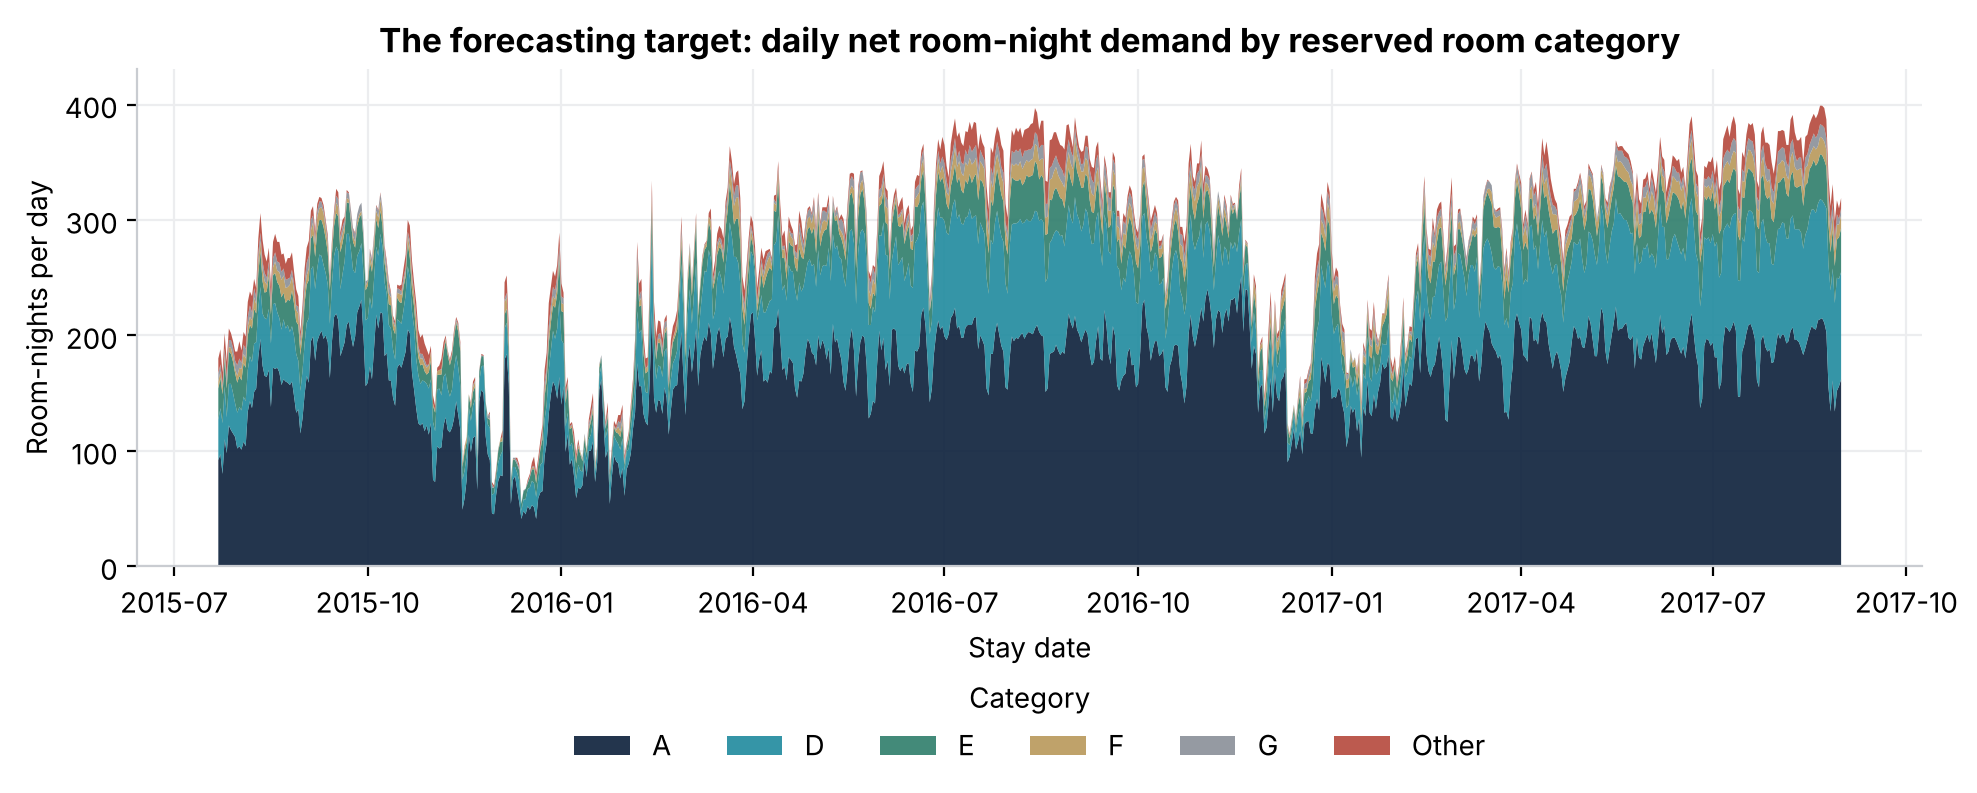

In [15]:
show('target_series')

## 15. Feature leakage audit (live demonstration)
Features for an origin date must be identical when the booking history is truncated at that date.

In [16]:
from src.feature_engineering import FeatureBuilder, truncate_as_of, FEATURE_COLUMNS
for origin in ['2016-03-10', '2017-06-15']:
    t = pd.Timestamp(origin)
    full = d.builder.make_rows([t])[FEATURE_COLUMNS]
    hidden = FeatureBuilder(truncate_as_of(d.clean, t)).make_rows([t])[FEATURE_COLUMNS]
    print(origin, 'features identical with future hidden:', full.equals(hidden))

2016-03-10 features identical with future hidden: True


2017-06-15 features identical with future hidden: True


## 16. Chronological split and results summary (from `reports/metrics.json`)

In [17]:
m = json.load(open(config.METRICS_FILE))
print('Split by target date:', m['split'], '| rows:', m['rows'])
rows = [{'model': 'Naive seasonal baseline', **{f'{p}_{k}': m['baseline'][p]['overall_1_14d'][k] for p in ('validation','test') for k in ('MAE','RMSE','WAPE')}}]
rows += [{'model': n, **{f'{p}_{k}': v[p]['overall_1_14d'][k] for p in ('validation','test') for k in ('MAE','RMSE','WAPE')}} for n, v in m['models'].items()]
pd.DataFrame(rows).round(3)

Split by target date: {'first': '2015-08-19', 'train_end': '2017-01-20', 'val_end': '2017-05-11', 'test_end': '2017-08-31'} | rows: {'train': 43218, 'validation': 9324, 'test': 9408}


,model,validation_MAE,validation_RMSE,validation_WAPE,test_MAE,test_RMSE,test_WAPE
0,Naive seasonal baseline,9.181,15.392,0.190,6.310,11.625,0.107
1,Linear Regression,3.141,5.569,0.065,2.358,3.793,0.040
2,Random Forest,2.769,5.706,0.057,1.892,3.363,0.032
3,HistGradientBoosting,2.565,5.204,0.053,1.804,3.147,0.030


In [18]:
print('Selected on validation:', m['selected_model'])
print('Without on-the-books features (ablation) test WAPE:', m['ablation_without_on_the_books']['test']['overall_1_14d']['WAPE'])

Selected on validation: HistGradientBoosting
Without on-the-books features (ablation) test WAPE: 0.08
